# Vibration of cylinders with integral blade stringers: Sewall and Naumann (1968)

J. L. Sewall and E. C. Naumann, *An experimental and analytical vibration study of thin cylindrical shells with and without longitudinal stiffeners*, NASA TN D-4705, September 1968 (NTRS 19680024266).
D. M. Egle and J. L. Sewall, *An analysis of free vibration of orthogonally stiffened cylindrical shells with stiffeners treated as discrete elements*, AIAA Journal 6(3) (1968) 518-526, https://doi.org/10.2514/3.4528.

Three aluminium cylinders of the same radius and skin thickness were vibration-tested at NASA Langley: an unstiffened shell (U), and two shells machined with 60 integral rectangular (blade) stringers, inside (IS, internally stiffened) or outside (ES, externally stiffened) the skin. Each was tested free-free (FF), simply supported (SS), clamped-free (CF) and clamped-clamped (CC), and the resonant frequencies are tabulated for each pair of wave numbers $(m, n)$ (Tables II to V of the report). Egle and Sewall (1968) computed the frequencies of the ES shell, simply supported, with the stringers treated as discrete elements (their Table 2).

This notebook models the three shells with `panels`: the skin as curved panels between the stringers and each stringer as a flat plate strip, a `MultiDomain` assembly. The natural frequencies are compared with every measured value, with the smeared-stringer analysis of Sewall and Naumann (their Figs. 8 to 11, digitised) and with the discrete- and averaged-stringer analyses of Egle and Sewall (their Table 2). Two variants of the stiffened shells are kept: the skin with its own circumferential bending stiffness, $D_y/D = 1$, and with the stiffness raised by the factor $D_y/D$ that Sewall and Naumann derive in their Appendix A for the stringer roots.

In [1]:
%matplotlib inline

import csv
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import blade_cylinder_utils as bu
from blade_cylinder_utils import IN, PSI, LBS2IN4


def pct(value, ref):
    return 100*(value - ref)/ref


def markdown_table(header, rows):
    out = ['| ' + ' | '.join(header) + ' |', '|' + '---|'*len(header)]
    out += ['| ' + ' | '.join(str(c) for c in row) + ' |' for row in rows]
    return Markdown('\n'.join(out))

## Test data

Table I of the report (p. 30) gives the averaged measured dimensions (stiffener dimensions averaged from 60 measurements) and the material of the three models, in U.S. Customary units with the SI values in parentheses. The material is 6061-T6 aluminium alloy; the shear modulus of the stringers, $G_s = 3.8 \times 10^6$ psi, is $E/(2(1 + \mu))$ of the tabulated $E$ and $\mu$, so the material is taken as isotropic. The 60 stringers are spaced 1.00 in along the middle surface of the skin (p. 6 and Table I), $2\pi R/60 = 0.998$ in (derived). The stringer height is measured from the skin surface: the tabulated stringer area is the rectangle $0.100 \times 0.2754$ in plus the two fillets of radius $r_F = 1/16$ in, $0.02754 + 2 r_F^2 (1 - \pi/4) = 0.02922$ in$^2$ (derived), against $A_s = 0.029219$ in$^2$.

The length between the supports differs with the boundary conditions (Table I): the clamped ends were potted 1/2 in deep (p. 7).

In [2]:
# Sewall and Naumann (1968), Table I (p. 30), in, psi, lb-s^2/in^4
TABLE_I = {
    'IS': dict(R=9.535, h=0.0266, rF=1/16, width=0.100, height=0.2754,
               As=0.029219, zs=-0.1438, Jes=0.832256e-3),
    'U': dict(R=9.538, h=0.0255),
    'ES': dict(R=9.537, h=0.0256, rF=1/16, width=0.100, height=0.2764,
               As=0.029319, zs=0.1439, Jes=0.836124e-3),
}
LENGTH = {'FF': 25.125, 'CF': 24.625, 'SS': 24.00, 'CC': 24.00}
E_PSI, NU, RHO_US = 1.e7, 0.315, 2.54e-4
NSTIFF = 60
E, RHO = E_PSI*PSI, RHO_US*LBS2IN4
print('1 in = %.4f m, 1 psi = %.3f Pa, 1 lb-s^2/in^4 = %.1f kg/m^3' % (IN, PSI, LBS2IN4))
print('E = %.0f psi = %.2f GPa (Table I: 68.95 GN/m^2)' % (E_PSI, E/1e9))
print('rho = %.2e lb-s^2/in^4 = %.1f kg/m^3 (Table I: 2.7145e3 kg/m^3)' % (RHO_US, RHO))
rows = []
for key in ('IS', 'U', 'ES'):
    t = TABLE_I[key]
    rows.append([key, '%.3f (%.1f)' % (t['R'], t['R']*IN*1e3),
                 '%.4f (%.3f)' % (t['h'], t['h']*IN*1e3),
                 '%.4f (%.3f)' % (t['height'], t['height']*IN*1e3) if 'height' in t else '-',
                 '%.3f (%.3f)' % (t['width'], t['width']*IN*1e3) if 'width' in t else '-'])
display(markdown_table(['model', 'R, in (mm)', 'h, in (mm)', 'stringer height, in (mm)',
                        'stringer width, in (mm)'], rows))
display(markdown_table(['ends', 'L, in (mm)'],
                       [[k, '%.3f (%.1f)' % (v, v*IN*1e3)] for k, v in LENGTH.items()]))

1 in = 0.0254 m, 1 psi = 6894.757 Pa, 1 lb-s^2/in^4 = 10686895.2 kg/m^3
E = 10000000 psi = 68.95 GPa (Table I: 68.95 GN/m^2)
rho = 2.54e-04 lb-s^2/in^4 = 2714.5 kg/m^3 (Table I: 2.7145e3 kg/m^3)


| model | R, in (mm) | h, in (mm) | stringer height, in (mm) | stringer width, in (mm) |
|---|---|---|---|---|
| IS | 9.535 (242.2) | 0.0266 (0.676) | 0.2754 (6.995) | 0.100 (2.540) |
| U | 9.538 (242.3) | 0.0255 (0.648) | - | - |
| ES | 9.537 (242.2) | 0.0256 (0.650) | 0.2764 (7.021) | 0.100 (2.540) |

| ends | L, in (mm) |
|---|---|
| FF | 25.125 (638.2) |
| CF | 24.625 (625.5) |
| SS | 24.000 (609.6) |
| CC | 24.000 (609.6) |

The measured frequencies of Tables II (SS), III (FF), IV (CC) and V (CF), p. 31 and 32, are transcribed in `results/sewall1968_tests.csv`. For many $(m, n)$ two frequencies are given: dual resonances of the two preferred orientations of the circumferential mode (p. 11), compared below through their mean. In Table III (FF) the first value of each pair was obtained with the electrodynamic shaker and the second with the air shaker, which the authors consider more nearly correct for the lowest $m$ and $n$ (p. 10): the air-shaker value is the reference. The wave numbers follow Fig. 4 of the report: $n$ circumferential full waves; $m$ the longitudinal half-waves for SS and CC, $m = 1$ the first beam-like mode without node for CF, and $m = 0$ (no node) and $m = 1$ (one node) the two inextensional modes for FF.

In [3]:
TESTS = {}
with open('results/sewall1968_tests.csv') as f:
    for row in csv.DictReader(line for line in f if not line.startswith('#')):
        fa = float(row['f_a'])
        fb = float(row['f_b']) if row['f_b'] else None
        if fb is None:
            ref = fa
        elif row['bc'] == 'FF':
            ref = fb
        else:
            ref = (fa + fb)/2
        TESTS.setdefault((row['model'], row['bc']), {})[(int(row['m']), int(row['n']))] = (ref, fa, fb)
print('%d measured frequencies' % sum(len(v) for v in TESTS.values()))

298 measured frequencies


## Model

**Discrete stringers.** Each stringer is a flat plate strip (`plate_clpt_gl`, the classical laminated plate theory) of thickness equal to the stringer width, $t_b = 0.100$ in, standing normal to the skin; the skin between two stringers is a curved panel of the Sanders-Koiter cylindrical shell model (`cylshell_clpt_sanders`), which, unlike the Donnell model, remains accurate for the low circumferential wave numbers $n = 2$ to 4 of the free-free modes. The plate strip is connected to the skin with the base-flange connection `'BFycte'`, which makes the displacements and the rotation about the stringer axis continuous at the root of the blade, and consecutive skin panels with `'SSycte'`; both are imposed exactly with `conn_method='null-space'` (Castro and Donadon 2017, https://doi.org/10.1016/j.compstruct.2016.10.026). The stringer eccentricity, which the smeared theories of the report introduce through the distance $\bar{z}_s$ of the stringer centroid from the middle surface, follows here from the geometry: the blade starts at the middle surface of the skin and ends at the stringer tip, its width $h_b = h/2 + $ height. The local axes of the blade are those of the skin rotated by 90 deg about $x$, its $y$ axis pointing inwards: the blade stands inside the skin when it is connected at its edge $y = 0$ and outside when connected at $y = h_b$ (see `bu.build_cylinder`).

The blade overlaps the skin over $h/2$, which replaces approximately the two fillets that the plate strips cannot represent. The table compares the stringer of the model with Table I: area $A = t_b h_b$, centroid $\bar{z} = \pm h_b/2$ and polar moment of inertia about the line of the middle surface under the stringer, $J_e = t_b h_b^3/3 + h_b t_b^3/12$.

In [4]:
BLADE = {}
rows = []
for key in ('IS', 'ES'):
    t = TABLE_I[key]
    tb, hb = t['width'], t['h']/2 + t['height']
    BLADE[key] = (tb*IN, hb*IN)
    A, z, Je = tb*hb, hb/2*np.sign(t['zs']), tb*hb**3/3 + hb*tb**3/12
    rows.append([key, '%.4f' % hb, '%.6f (%+.1f%%)' % (A, pct(A, t['As'])),
                 '%+.4f (%+.1f%%)' % (z, pct(z, t['zs'])),
                 '%.4e (%+.1f%%)' % (Je, pct(Je, t['Jes']))])
display(markdown_table(['model', 'h_b, in', 'A, in^2 (vs A_s)', 'z, in (vs z_s)', 'J_e, in^4 (vs J_es)'], rows))

| model | h_b, in | A, in^2 (vs A_s) | z, in (vs z_s) | J_e, in^4 (vs J_es) |
|---|---|---|---|---|
| IS | 0.2887 | 0.028870 (-1.2%) | -0.1443 (+0.4%) | 8.2614e-04 (-0.7%) |
| ES | 0.2892 | 0.028920 (-1.4%) | +0.1446 (+0.5%) | 8.3036e-04 (-0.7%) |

### Circumferential bending stiffness at the stringer roots, $D_y/D$

In the model each blade is joined to the skin along a line, and the skin keeps the thickness $h$ up to the blade. In the test shells the stringer root is $2 r_S = 0.100$ in wide, with two fillets of radius $r_F = 1/16$ in, which stiffen the skin in circumferential bending. Appendix A of the report (pp. 23 to 26) estimates this effect, after Huffington, Schumacher and Irwin (Ref. 24 of the report), by requiring that a stringer pitch $d$ in pure circumferential bending store the same strain energy as an equivalent orthotropic shell, with the neutral surface at the mid-height of the shell-stringer combination (Eq. A1, p. 23):

$$\frac{D_y}{D} = \frac{1}{\dfrac{h^3}{d} \displaystyle\int_{-d/2}^{d/2} \frac{dy}{[h(y)]^3}}$$

The effective thickness $h(y)$ is $h$ in the bay and follows quarter-circular arcs through the fillets and the stringer (sketch c, p. 24), with $b = h + r_F$; the integral is the sum of the bay, $I_C = (d - 2(r_F + r_S))/h^3$ (Eq. A3), the two fillets, $I_F$ (Eq. A4), and the stringer, $I_S$ (Eq. A5), and $D_y/D = 1/[h^3 (I_C + 2 I_F + I_S)/d]$ (Eq. A6). With $h$, $r_F$, $r_S$ and $d$ of Table I the report obtains $D_y/D = 1.197$ for the ES shell and $1.195$ for the IS shell, and "the analytical frequencies given in figures 8 to 11 are based on these values" (p. 25). With the stringer part simplified to $I_S = 2 r_S/b^3$ it gives 1.195 (ES) and 1.192 (IS), and as bounds 1.29 for infinitely thick fillets and stringer (Eq. A7) and 1.11 for a stringer without fillets with $h/b \to 0$ (Eq. A8) (p. 26). Egle and Sewall use $D_y/D = 1.197$ for the ES shell (Table 1, p. 522).

The cell recomputes these values from Table I, with the closed forms (A3) to (A6) and, as a check, by quadrature of (A1) with $h(y)$ of sketch c.

In [5]:
from scipy.integrate import quad


def dy_over_d(h, rF, rS, d, simplified=False):
    # Sewall and Naumann (1968), Eqs. (A3) to (A6)
    b = h + rF
    IC = (d - 2*(rF + rS))/h**3
    IF = rF/2*((b**2 + rF**2)/(b*(b**2 - rF**2)**2) + b/((b - rF)**2*(b + rF)**2)
               + 6*b*rF/(b**2 - rF**2)**2.5*np.arctan(np.sqrt((b + rF)/(b - rF))))
    if simplified:
        IS = 2*rS/b**3
    else:
        IS = rS*((b**2 + rS**2)/(b*(b**2 - rS**2)**2) + b/((b - rS)**2*(b + rS)**2)
                 - 6*b*rS/(b**2 - rS**2)**2.5*np.arctan(np.sqrt((b - rS)/(b + rS))))
    return 1/(h**3/d*(IC + 2*IF + IS))


def dy_over_d_quadrature(h, rF, rS, d):
    # Eq. (A1) with h(y) of sketch c
    b = h + rF

    def hy(y):
        y = abs(y)
        if y <= rS:
            return b + np.sqrt(rS**2 - y**2)
        if y <= rS + rF:
            return b - np.sqrt(max(rF**2 - (y - rS - rF)**2, 0.))
        return h
    integral = quad(lambda y: hy(y)**-3, -d/2, d/2, points=[-rS - rF, -rS, rS, rS + rF],
                    limit=200)[0]
    return 1/(h**3/d*integral)


SPACING = 1.00  # d, in, Table I
DY_REPORT = {'IS': 1.195, 'ES': 1.197}             # p. 25
DY_REPORT_SIMPLIFIED = {'IS': 1.192, 'ES': 1.195}  # p. 26
rows = []
for key in ('IS', 'ES'):
    t = TABLE_I[key]
    args = (t['h'], t['rF'], t['width']/2, SPACING)
    rows.append([key, '%.4f' % t['h'], '%.4f' % dy_over_d(*args), '%.4f' % dy_over_d_quadrature(*args),
                 '%.3f' % DY_REPORT[key], '%.4f' % dy_over_d(*args, simplified=True),
                 '%.3f' % DY_REPORT_SIMPLIFIED[key]])
display(markdown_table(['shell', 'h, in', 'D_y/D, (A6)', 'D_y/D, (A1) by quadrature', 'report, p. 25',
                        'D_y/D with I_S = 2 r_S/b^3', 'report, p. 26'], rows))
rF, rS = 1/16, 0.100/2
print('bound (A7), 1/(1 - 2(r_F + r_S)/d) = %.3f (report, p. 26: 1.29)' % (1/(1 - 2*(rF + rS)/SPACING)))
print('bound (A8) for h/b -> 0, 1/(1 - 2 r_S/d) = %.3f (report, p. 26: 1.11)' % (1/(1 - 2*rS/SPACING)))
DY = DY_REPORT

| shell | h, in | D_y/D, (A6) | D_y/D, (A1) by quadrature | report, p. 25 | D_y/D with I_S = 2 r_S/b^3 | report, p. 26 |
|---|---|---|---|---|---|---|
| IS | 0.0266 | 1.1952 | 1.1952 | 1.195 | 1.1927 | 1.192 |
| ES | 0.0256 | 1.1966 | 1.1966 | 1.197 | 1.1943 | 1.195 |

bound (A7), 1/(1 - 2(r_F + r_S)/d) = 1.290 (report, p. 26: 1.29)
bound (A8) for h/b -> 0, 1/(1 - 2 r_S/d) = 1.111 (report, p. 26: 1.11)


The closed forms and the quadrature agree, and both reproduce the values of the report, 1.195 (IS) and 1.197 (ES), and the two bounds. The simplified values differ from those printed on p. 26 in the last digit. The report uses the factors of p. 25 for its analytical curves, and so does the variant here.

**The variant in `panels`.** As in the report and in Egle and Sewall, the factor is applied to the whole skin: the circumferential bending stiffness $D_{22}$ of every skin panel is multiplied by $D_y/D$, and nothing else changes (`bu.build_cylinder(..., Dy_factor=...)`). The constitutive matrix of a `Shell`, `Shell.ABD`, comes from its laminate and is read-only; a matrix that does not come from a stack of plies is given through the attribute `ABDnxny` (see `panels.shell.Shell`). The helper copies `Shell.ABD` of the isotropic skin, multiplies its entry $D_{22}$ (row and column 5, in the order $\varepsilon_{xx}, \varepsilon_{yy}, \gamma_{xy}, \kappa_{xx}, \kappa_{yy}, \kappa_{xy}$) and sets the result as `ABDnxny`. The stiffness matrix of the panel is then integrated numerically, exactly with the default number of Gauss points, and the mass matrix still comes from the laminate. The report also raises the coupling stiffness: with $D_x/D = 1$ and $\mu = 0.315$, $D_1/D = 0.346$ (p. 17), which is $\mu (D_x + D_y)/(2 D)$, the form of the strain energy of Egle and Sewall (Eq. 2, p. 519). The variant keeps $D_{12} = \mu D$; the effect of $D_{12}$ is checked in the section on sensitivities.

Check: with `ABDnxny` equal to the unchanged matrix of the laminate, the numerically integrated model gives the frequencies of the analytically integrated one (SS, IS shell, few terms):

In [6]:
t = TABLE_I['IS']
tb, hb = BLADE['IS']
args = (t['R']*IN, t['h']*IN, LENGTH['SS']*IN, E, NU, RHO)
kw = dict(nstiff=NSTIFF, tb=tb, hb=hb, side='internal', bc='SS', mx=10, ny=6, nyb=4)
low = {}
for numerical in (False, True):
    md, skin, blades = bu.build_cylinder(*args, **kw)
    if numerical:
        for p in skin:
            p.ABDnxny = np.array(p.ABD)
    modes, dt, rres = bu.frequencies(md, skin, t['R']*IN, 'SS', num_eigvalues=40)
    low[numerical] = bu.lowest_by_mn(modes)
    print('%s integration: %.1f s' % ('numerical' if numerical else 'analytical', dt))
common = [mn for mn in low[False] if mn in low[True]]
print('%d (m, n) in common, largest relative difference %.1e'
      % (len(common), max(abs(pct(low[True][mn], low[False][mn])/100) for mn in common)))

analytical integration: 6.8 s


numerical integration: 10.3 s
39 (m, n) in common, largest relative difference 2.3e-11


**Symmetry.** The 60 stringers are identical and equally spaced, and the measured circumferential mode shapes are close to a single harmonic (Fig. 5(a) of the report; Egle and Sewall found the second Fourier coefficient of the discrete-stringer modes at least six orders of magnitude below the first, p. 523). Every mode $w \propto \cos n\theta$ is symmetric about the plane $\theta = 0$ and about $\theta = \pi$, so half of the cylinder, bounded by two symmetry planes through the middle of a bay ($v = w_{,y} = 0$), contains one mode of each pair for every $n$, with 30 stringers, 29 full bays and two half bays. The other mode of the pair, $\sin n\theta$, has the same frequency for a perfectly axisymmetric shell and almost the same for 60 stringers; the check below compares the half and the full cylinder for one case.

**Boundary conditions** (p. 6 to 8 and sketches a and b), as boundary flags of the Ritz functions at each end (`bu.END_FLAGS`):

| ends | test | skin | blades |
|---|---|---|---|
| SS | knife-edge rings inside and outside the shell, longitudinal motion permitted | $v = w = 0$ | radial displacement 0 (the ring on the stiffened side bears on the stringer tips) |
| C (of CC, CF) | potted 1/2 in deep in a low-melting-point alloy | $u = v = w = w_{,x} = 0$ | $u = v = w = 0$, $v_{,x} = w_{,x} = 0$ |
| F | free (FF suspended on soft rubber bands) | free | free |

The six rigid-body modes of the free-free shell (fewer in the half model) have zero frequency and are excluded.

The figure shows a sector of the cross-sections of the two models, with the blades to scale.

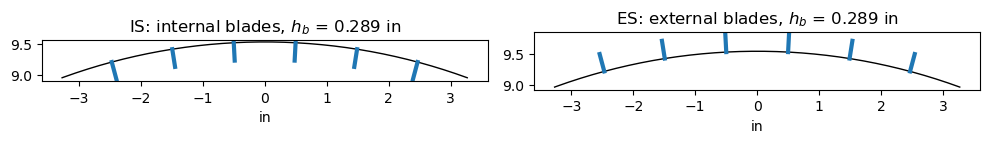

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, key, side in zip(axes, ('IS', 'ES'), ('internal', 'external')):
    t = TABLE_I[key]
    R = t['R']
    tb, hb = BLADE[key]
    th = np.linspace(np.pi/2 - 0.35, np.pi/2 + 0.35, 200)
    ax.plot(R*np.cos(th), R*np.sin(th), 'k-', lw=1)
    for k in range(-3, 3):
        thk = np.pi/2 + (k + 0.5)*2*np.pi/NSTIFF
        r2 = R - hb/IN if side == 'internal' else R + hb/IN
        ax.plot([R*np.cos(thk), r2*np.cos(thk)], [R*np.sin(thk), r2*np.sin(thk)], 'C0-', lw=3)
    ax.set_aspect('equal')
    ax.set_title('%s: %s blades, $h_b$ = %.3f in' % (key, side, hb/IN))
    ax.set_xlabel('in')
plt.tight_layout()
plt.show()

### Check of the half model

The simply supported IS shell, with a coarse number of terms, as a half and as a full cylinder: lowest frequency of each $(m, n)$ with $m \le 2$, $n \le 10$. In the full cylinder each $n$ appears twice ($\cos n\theta$ and $\sin n\theta$); the lower one is shown.

In [8]:
t = TABLE_I['IS']
tb, hb = BLADE['IS']
args = (t['R']*IN, t['h']*IN, LENGTH['SS']*IN, E, NU, RHO)
kw = dict(nstiff=NSTIFF, tb=tb, hb=hb, side='internal', bc='SS', mx=10, ny=6, nyb=4)
out = {}
for full in (False, True):
    md, skin, blades = bu.build_cylinder(*args, full=full, **kw)
    modes, dt, rres = bu.frequencies(md, skin, t['R']*IN, 'SS', num_eigvalues=80 if full else 40)
    out[full] = bu.lowest_by_mn(modes)
    print('%s cylinder: %d dofs before the connections, %.1f s, max. relative residual %.1e'
          % ('full' if full else 'half', md.get_size(), dt, rres))
rows = []
for mn in sorted(out[False]):
    if mn[0] <= 2 and 2 <= mn[1] <= 10 and mn in out[True]:
        rows.append(['%d, %d' % mn, '%.2f' % out[False][mn], '%.2f' % out[True][mn],
                     '%+.3f%%' % pct(out[False][mn], out[True][mn])])
display(markdown_table(['m, n', 'half, Hz', 'full, Hz', 'half vs full'], rows))

half cylinder: 9060 dofs before the connections, 6.2 s, max. relative residual 7.4e-08


full cylinder: 18000 dofs before the connections, 23.7 s, max. relative residual 1.5e-07


| m, n | half, Hz | full, Hz | half vs full |
|---|---|---|---|
| 1, 2 | 628.04 | 628.03 | +0.001% |
| 1, 3 | 368.75 | 368.75 | +0.000% |
| 1, 4 | 233.12 | 233.12 | +0.000% |
| 1, 5 | 165.01 | 165.01 | +0.000% |
| 1, 6 | 139.42 | 139.42 | +0.000% |
| 1, 7 | 142.02 | 142.02 | +0.000% |
| 1, 8 | 161.26 | 161.26 | +0.000% |
| 1, 9 | 189.85 | 189.85 | +0.000% |
| 1, 10 | 224.36 | 224.36 | +0.000% |
| 2, 4 | 652.68 | 652.68 | +0.001% |
| 2, 5 | 485.19 | 485.19 | +0.000% |
| 2, 6 | 383.97 | 383.97 | +0.000% |
| 2, 7 | 332.18 | 332.18 | +0.000% |
| 2, 8 | 316.53 | 316.53 | +0.000% |
| 2, 9 | 325.22 | 325.22 | +0.000% |
| 2, 10 | 349.12 | 349.12 | +0.000% |

## Convergence

The number of Ritz terms is increased in four steps, $m_x$ along $x$ (skin and blades, the same such that the connections along $x$ are exact), $n_y$ across a full skin bay and $n_b$ across a blade (at least 4, the minimum for which the base-flange connection does not lock, see `MultiDomain.check_conn_terms`). The table gives, for each shell and boundary condition, the largest relative change of the frequencies of all the measured $(m, n)$ from the previous step. The column residual is the largest relative residual of the eigenpairs, $\|(\boldsymbol{K} - \omega^2 \boldsymbol{M}) \boldsymbol{\phi}\| / \|\boldsymbol{K} \boldsymbol{\phi}\|$. The study is made for both variants of the stiffened shells ($D_y/D = 1$ and $D_y/D$ of Appendix A). The last step is used in the comparisons, and its frequencies are written to `results/sewall1968_blade_cylinder_frequencies.csv`.

In [9]:
LEVELS = [(8, 4, 4), (10, 6, 4), (12, 8, 5), (14, 10, 6)]
NUM_EIGVALUES = 200
BCS = ('SS', 'FF', 'CC', 'CF')
VARIANT = {0: 'D_y/D = 1', 1: 'D_y/D, App. A'}
CASES = ([(key, bc, 0) for key in ('U', 'IS', 'ES') for bc in BCS]
         + [(key, bc, 1) for key in ('IS', 'ES') for bc in BCS])
RES = {}
MODES = {}
rows = []
for key, bc, var in CASES:
    t = TABLE_I[key]
    R = t['R']*IN
    tb, hb = BLADE.get(key, (None, None))
    side = 'internal' if key == 'IS' else 'external'
    dyf = DY[key] if var else 1.
    prev = None
    for i, (mx, ny, nyb) in enumerate(LEVELS):
        md, skin, blades = bu.build_cylinder(R, t['h']*IN, LENGTH[bc]*IN, E, NU, RHO,
                nstiff=NSTIFF, tb=tb, hb=hb, side=side, bc=bc, mx=mx, ny=ny, nyb=nyb,
                Dy_factor=dyf)
        modes, dt, rres = bu.frequencies(md, skin, R, bc, num_eigvalues=NUM_EIGVALUES)
        low = bu.lowest_by_mn(modes)
        RES[(key, bc, var, i)] = low
        common = [mn for mn in TESTS[(key, bc)] if mn in low and prev is not None and mn in prev]
        change = max(abs(pct(low[mn], prev[mn])) for mn in common) if common else float('nan')
        rows.append([key, bc, '%.3f' % dyf, '%d, %d, %d' % (mx, ny, nyb), md.get_size(),
                     '%.0f' % modes[-1][0], '%.1f' % dt, '%.0e' % rres,
                     '-' if prev is None else '%.2f%%' % change])
        prev = low
    # the mode of lowest frequency with n >= 2, for the plots of the mode shapes
    MODES[(key, bc, var)] = (md, skin, next(mode for mode in modes if mode[2] >= 2))
display(markdown_table(['shell', 'ends', 'D_y/D', 'm_x, n_y, n_b', 'dofs', 'highest f, Hz', 'time, s',
                        'residual', 'max. change'], rows))
FINAL = len(LEVELS) - 1
FIN = {(key, bc, var): RES[(key, bc, var, FINAL)] for key, bc, var in CASES}
with open('results/sewall1968_blade_cylinder_frequencies.csv', 'w', newline='') as f:
    f.write('# panels, notebook sewall1968_blade_cylinder_vibration.ipynb: natural frequencies of the\n'
            '# Sewall and Naumann (1968) shells, half-cylinder MultiDomain model, terms (m_x, n_y, n_b) = '
            '(%d, %d, %d),\n' % LEVELS[FINAL]
            + '# lowest frequency of each (m, n) among the %d lowest modes; Dy_over_D: factor of the\n'
            % NUM_EIGVALUES
            + '# circumferential bending stiffness of the skin (Appendix A of the report), 1 for the\n'
            '# plate stringers alone. shell U/IS/ES, ends SS/FF/CC/CF, f_Hz in Hz.\n')
    w = csv.writer(f)
    w.writerow(['shell', 'ends', 'Dy_over_D', 'm', 'n', 'f_Hz'])
    for key, bc, var in CASES:
        for (m, n), fr in sorted(FIN[(key, bc, var)].items()):
            w.writerow([key, bc, DY[key] if var else 1.0, m, n, '%.3f' % fr])

| shell | ends | D_y/D | m_x, n_y, n_b | dofs | highest f, Hz | time, s | residual | max. change |
|---|---|---|---|---|---|---|---|---|
| U | SS | 1.000 | 8, 4, 4 | 2976 | 3299 | 26.3 | 5e-07 | - |
| U | SS | 1.000 | 10, 6, 4 | 5460 | 2446 | 26.8 | 2e-06 | 0.58% |
| U | SS | 1.000 | 12, 8, 5 | 8640 | 2328 | 31.2 | 5e-07 | 0.00% |
| U | SS | 1.000 | 14, 10, 6 | 12600 | 2028 | 36.4 | 6e-06 | 0.00% |
| U | FF | 1.000 | 8, 4, 4 | 2976 | 2370 | 26.0 | 1e-05 | - |
| U | FF | 1.000 | 10, 6, 4 | 5460 | 2165 | 28.6 | 2e-05 | 0.55% |
| U | FF | 1.000 | 12, 8, 5 | 8640 | 1827 | 34.1 | 1e-04 | 0.12% |
| U | FF | 1.000 | 14, 10, 6 | 12600 | 1763 | 38.3 | 2e-04 | 0.09% |
| U | CC | 1.000 | 8, 4, 4 | 2976 | 7708 | 25.2 | 1e-08 | - |
| U | CC | 1.000 | 10, 6, 4 | 5460 | 3163 | 26.6 | 8e-08 | 1.37% |
| U | CC | 1.000 | 12, 8, 5 | 8640 | 2343 | 31.9 | 1e-07 | 0.75% |
| U | CC | 1.000 | 14, 10, 6 | 12600 | 2072 | 36.5 | 2e-07 | 0.36% |
| U | CF | 1.000 | 8, 4, 4 | 2976 | 3306 | 25.4 | 3e-07 | - |
| U | CF | 1.000 | 10, 6, 4 | 5460 | 2527 | 25.7 | 8e-07 | 0.64% |
| U | CF | 1.000 | 12, 8, 5 | 8640 | 2063 | 31.4 | 2e-06 | 0.33% |
| U | CF | 1.000 | 14, 10, 6 | 12600 | 1936 | 37.9 | 4e-06 | 0.16% |
| IS | SS | 1.000 | 8, 4, 4 | 5856 | 3525 | 26.8 | 4e-07 | - |
| IS | SS | 1.000 | 10, 6, 4 | 9060 | 2825 | 28.5 | 1e-06 | 1.24% |
| IS | SS | 1.000 | 12, 8, 5 | 14040 | 2733 | 31.2 | 7e-07 | 0.12% |
| IS | SS | 1.000 | 14, 10, 6 | 20160 | 2603 | 37.6 | 1e-06 | 0.12% |
| IS | FF | 1.000 | 8, 4, 4 | 5856 | 2556 | 23.9 | 2e-04 | - |
| IS | FF | 1.000 | 10, 6, 4 | 9060 | 2190 | 26.9 | 2e-04 | 0.35% |
| IS | FF | 1.000 | 12, 8, 5 | 14040 | 2067 | 31.4 | 4e-05 | 0.02% |
| IS | FF | 1.000 | 14, 10, 6 | 20160 | 2027 | 38.0 | 2e-05 | 0.03% |
| IS | CC | 1.000 | 8, 4, 4 | 5856 | 4347 | 23.2 | 9e-08 | - |
| IS | CC | 1.000 | 10, 6, 4 | 9060 | 3004 | 24.4 | 4e-07 | 3.42% |
| IS | CC | 1.000 | 12, 8, 5 | 14040 | 2918 | 29.5 | 3e-07 | 0.47% |
| IS | CC | 1.000 | 14, 10, 6 | 20160 | 2853 | 36.1 | 9e-08 | 0.18% |
| IS | CF | 1.000 | 8, 4, 4 | 5856 | 3306 | 25.4 | 3e-06 | - |
| IS | CF | 1.000 | 10, 6, 4 | 9060 | 2545 | 26.7 | 9e-06 | 0.56% |
| IS | CF | 1.000 | 12, 8, 5 | 14040 | 2376 | 30.5 | 6e-05 | 0.14% |
| IS | CF | 1.000 | 14, 10, 6 | 20160 | 2357 | 38.1 | 8e-07 | 0.09% |
| ES | SS | 1.000 | 8, 4, 4 | 5856 | 3484 | 25.1 | 2e-07 | - |
| ES | SS | 1.000 | 10, 6, 4 | 9060 | 2813 | 26.8 | 4e-07 | 0.46% |
| ES | SS | 1.000 | 12, 8, 5 | 14040 | 2710 | 31.4 | 4e-06 | 0.09% |
| ES | SS | 1.000 | 14, 10, 6 | 20160 | 2702 | 40.3 | 4e-07 | 0.09% |
| ES | FF | 1.000 | 8, 4, 4 | 5856 | 2466 | 25.0 | 2e-04 | - |
| ES | FF | 1.000 | 10, 6, 4 | 9060 | 2236 | 27.4 | 2e-04 | 0.38% |
| ES | FF | 1.000 | 12, 8, 5 | 14040 | 2168 | 32.6 | 2e-05 | 0.02% |
| ES | FF | 1.000 | 14, 10, 6 | 20160 | 2150 | 39.0 | 1e-04 | 0.03% |
| ES | CC | 1.000 | 8, 4, 4 | 5856 | 4302 | 22.7 | 7e-08 | - |
| ES | CC | 1.000 | 10, 6, 4 | 9060 | 3077 | 25.9 | 2e-07 | 0.78% |
| ES | CC | 1.000 | 12, 8, 5 | 14040 | 2917 | 29.1 | 2e-07 | 0.43% |
| ES | CC | 1.000 | 14, 10, 6 | 20160 | 2879 | 33.9 | 6e-08 | 0.28% |
| ES | CF | 1.000 | 8, 4, 4 | 5856 | 3340 | 23.9 | 7e-06 | - |
| ES | CF | 1.000 | 10, 6, 4 | 9060 | 2609 | 26.1 | 6e-06 | 0.55% |
| ES | CF | 1.000 | 12, 8, 5 | 14040 | 2493 | 30.7 | 3e-05 | 0.28% |
| ES | CF | 1.000 | 14, 10, 6 | 20160 | 2481 | 37.1 | 8e-06 | 0.18% |
| IS | SS | 1.195 | 8, 4, 4 | 5856 | 3697 | 25.2 | 5e-08 | - |
| IS | SS | 1.195 | 10, 6, 4 | 9060 | 2905 | 31.1 | 5e-07 | 1.18% |
| IS | SS | 1.195 | 12, 8, 5 | 14040 | 2819 | 47.2 | 8e-07 | 0.12% |
| IS | SS | 1.195 | 14, 10, 6 | 20160 | 2683 | 87.2 | 8e-06 | 0.11% |
| IS | FF | 1.195 | 8, 4, 4 | 5856 | 2670 | 24.4 | 2e-04 | - |
| IS | FF | 1.195 | 10, 6, 4 | 9060 | 2260 | 30.6 | 2e-05 | 0.29% |
| IS | FF | 1.195 | 12, 8, 5 | 14040 | 2132 | 49.2 | 6e-05 | 0.02% |
| IS | FF | 1.195 | 14, 10, 6 | 20160 | 2111 | 86.9 | 3e-05 | 0.02% |
| IS | CC | 1.195 | 8, 4, 4 | 5856 | 4646 | 22.9 | 7e-08 | - |
| IS | CC | 1.195 | 10, 6, 4 | 9060 | 3127 | 27.6 | 2e-07 | 3.25% |
| IS | CC | 1.195 | 12, 8, 5 | 14040 | 3026 | 41.8 | 1e-07 | 0.45% |
| IS | CC | 1.195 | 14, 10, 6 | 20160 | 2925 | 79.1 | 3e-08 | 0.18% |
| IS | CF | 1.195 | 8, 4, 4 | 5856 | 3540 | 23.6 | 7e-06 | - |
| IS | CF | 1.195 | 10, 6, 4 | 9060 | 2619 | 29.1 | 1e-05 | 0.49% |
| IS | CF | 1.195 | 12, 8, 5 | 14040 | 2481 | 45.6 | 5e-05 | 0.14% |
| IS | CF | 1.195 | 14, 10, 6 | 20160 | 2449 | 87.8 | 8e-06 | 0.08% |
| ES | SS | 1.197 | 8, 4, 4 | 5856 | 3701 | 24.3 | 7e-07 | - |
| ES | SS | 1.197 | 10, 6, 4 | 9060 | 2930 | 33.9 | 1e-06 | 0.40% |
| ES | SS | 1.197 | 12, 8, 5 | 14040 | 2825 | 52.3 | 2e-06 | 0.09% |
| ES | SS | 1.197 | 14, 10, 6 | 20160 | 2824 | 97.8 | 3e-05 | 0.08% |
| ES | FF | 1.197 | 8, 4, 4 | 5856 | 2651 | 27.3 | 8e-05 | - |
| ES | FF | 1.197 | 10, 6, 4 | 9060 | 2303 | 33.9 | 2e-04 | 0.32% |
| ES | FF | 1.197 | 12, 8, 5 | 14040 | 2220 | 50.8 | 3e-05 | 0.02% |
| ES | FF | 1.197 | 14, 10, 6 | 20160 | 2219 | 92.4 | 1e-04 | 0.02% |
| ES | CC | 1.197 | 8, 4, 4 | 5856 | 4584 | 24.3 | 4e-08 | - |
| ES | CC | 1.197 | 10, 6, 4 | 9060 | 3195 | 28.9 | 2e-07 | 0.77% |
| ES | CC | 1.197 | 12, 8, 5 | 14040 | 3025 | 43.8 | 1e-07 | 0.42% |
| ES | CC | 1.197 | 14, 10, 6 | 20160 | 3005 | 82.6 | 4e-09 | 0.28% |
| ES | CF | 1.197 | 8, 4, 4 | 5856 | 3524 | 24.5 | 1e-05 | - |
| ES | CF | 1.197 | 10, 6, 4 | 9060 | 2698 | 31.4 | 3e-05 | 0.53% |
| ES | CF | 1.197 | 12, 8, 5 | 14040 | 2571 | 46.1 | 2e-05 | 0.28% |
| ES | CF | 1.197 | 14, 10, 6 | 20160 | 2536 | 91.9 | 1e-05 | 0.18% |

## Comparison with the tests

For each boundary condition, the measured frequency (mean of a dual resonance, air shaker for FF) and the frequency of `panels` for the same $(m, n)$ (lowest mode classified with these wave numbers by `bu.classify`), with the relative difference; for the stiffened shells with $D_y/D = 1$ and with $D_y/D$ of Appendix A (columns "D_y").

In [10]:
SUMMARY = []
STATS = {}
for bc, table in (('SS', 'II'), ('FF', 'III'), ('CC', 'IV'), ('CF', 'V')):
    keys = sorted(set(mn for key in ('U', 'IS', 'ES') for mn in TESTS[(key, bc)]))
    rows = []
    for mn in keys:
        row = ['%d, %d' % mn]
        for key in ('U', 'IS', 'ES'):
            variants = (0,) if key == 'U' else (0, 1)
            test = TESTS[(key, bc)].get(mn)
            if test is None:
                row += ['']*(1 + len(variants))
                continue
            row.append('%.1f' % test[0])
            for var in variants:
                calc = FIN[(key, bc, var)].get(mn)
                row.append('not found' if calc is None else '%.1f (%+.1f%%)' % (calc, pct(calc, test[0])))
        rows.append(row)
    display(Markdown('**%s, Table %s of the report**' % (bc, table)))
    display(markdown_table(['m, n', 'U test, Hz', 'U panels', 'IS test, Hz', 'IS panels', 'IS panels, D_y',
                            'ES test, Hz', 'ES panels', 'ES panels, D_y'], rows))
    for key in ('U', 'IS', 'ES'):
        for var in ((0,) if key == 'U' else (0, 1)):
            calc = FIN[(key, bc, var)]
            d = [pct(calc[mn], v[0]) for mn, v in TESTS[(key, bc)].items() if mn in calc]
            STATS[('test', bc, key, var)] = d
            SUMMARY.append([bc, key, VARIANT[var] if key != 'U' else '-', len(d), '%+.1f%%' % np.mean(d),
                            '%.1f%%' % np.mean(np.abs(d)), '%+.1f%%' % min(d), '%+.1f%%' % max(d)])

**SS, Table II of the report**

| m, n | U test, Hz | U panels | IS test, Hz | IS panels | IS panels, D_y | ES test, Hz | ES panels | ES panels, D_y |
|---|---|---|---|---|---|---|---|---|
| 1, 4 | 287.0 | 287.5 (+0.2%) | 233.0 | 233.1 (+0.0%) | 233.4 (+0.2%) |  |  |  |
| 1, 5 | 207.0 | 201.8 (-2.5%) | 175.0 | 164.9 (-5.8%) | 166.1 (-5.1%) | 231.0 | 228.2 (-1.2%) | 229.1 (-0.8%) |
| 1, 6 | 175.0 | 166.5 (-4.8%) | 142.0 | 139.2 (-2.0%) | 142.3 (+0.2%) | 199.0 | 195.4 (-1.8%) | 197.5 (-0.7%) |
| 1, 7 | 166.0 | 166.2 (+0.1%) | 146.0 | 141.7 (-2.9%) | 147.4 (+1.0%) | 189.0 | 185.6 (-1.8%) | 189.8 (+0.4%) |
| 1, 8 | 188.0 | 189.2 (+0.7%) | 169.0 | 160.9 (-4.8%) | 169.5 (+0.3%) | 199.0 | 192.1 (-3.5%) | 199.0 (+0.0%) |
| 1, 9 | 224.0 | 226.8 (+1.3%) | 203.0 | 189.5 (-6.7%) | 201.2 (-0.9%) | 219.0 | 210.2 (-4.0%) | 220.3 (+0.6%) |
| 1, 10 | 268.0 | 274.0 (+2.2%) | 243.0 | 224.0 (-7.8%) | 239.1 (-1.6%) | 252.0 | 236.8 (-6.0%) | 250.3 (-0.7%) |
| 1, 11 | 326.0 | 328.5 (+0.8%) | 290.0 | 263.0 (-9.3%) | 281.8 (-2.8%) | 290.0 | 269.7 (-7.0%) | 287.1 (-1.0%) |
| 1, 12 | 383.5 | 389.4 (+1.5%) | 333.0 | 306.0 (-8.1%) | 328.8 (-1.3%) | 336.0 | 308.0 (-8.3%) | 329.5 (-1.9%) |
| 1, 13 | 440.0 | 456.1 (+3.7%) | 392.0 | 352.6 (-10.0%) | 379.8 (-3.1%) | 382.0 | 350.7 (-8.2%) | 376.6 (-1.4%) |
| 1, 14 |  |  | 450.0 | 402.8 (-10.5%) | 434.7 (-3.4%) | 440.0 | 397.5 (-9.7%) | 428.0 (-2.7%) |
| 1, 15 | 590.0 | 606.3 (+2.8%) | 502.0 | 456.4 (-9.1%) | 493.4 (-1.7%) | 500.0 | 448.0 (-10.4%) | 483.5 (-3.3%) |
| 2, 8 | 345.5 | 345.0 (-0.1%) | 319.0 | 316.0 (-1.0%) | 321.1 (+0.6%) |  |  |  |
| 2, 9 |  |  | 333.0 | 324.5 (-2.5%) | 332.3 (-0.2%) |  |  |  |
| 2, 10 | 340.5 | 341.6 (+0.3%) | 366.0 | 348.3 (-4.8%) | 359.1 (-1.9%) | 473.5 | 468.9 (-1.0%) | 476.7 (+0.7%) |
| 2, 11 | 369.5 | 374.8 (+1.4%) | 399.0 | 381.6 (-4.4%) | 395.7 (-0.8%) | 489.0 | 479.6 (-1.9%) | 490.5 (+0.3%) |
| 2, 12 | 410.0 | 423.0 (+3.2%) | 443.0 | 421.1 (-4.9%) | 439.1 (-0.9%) | 509.5 | 499.4 (-2.0%) | 514.0 (+0.9%) |
| 2, 13 | 475.0 | 482.1 (+1.5%) | 482.0 | 465.4 (-3.4%) | 487.5 (+1.1%) | 546.0 | 527.0 (-3.5%) | 545.8 (-0.0%) |
| 2, 14 |  |  | 555.5 | 513.7 (-7.5%) | 540.2 (-2.7%) | 590.0 | 561.2 (-4.9%) | 584.6 (-0.9%) |
| 2, 15 |  |  |  |  |  | 630.0 | 601.2 (-4.6%) | 629.5 (-0.1%) |
| 3, 8 |  |  | 603.5 | 581.9 (-3.6%) | 585.7 (-3.0%) |  |  |  |
| 3, 11 | 499.0 | 496.1 (-0.6%) | 622.0 | 601.8 (-3.3%) | 612.6 (-1.5%) |  |  |  |
| 3, 12 | 513.5 | 512.8 (-0.1%) | 664.0 | 635.4 (-4.3%) | 649.4 (-2.2%) |  |  |  |
| 3, 14 | 604.0 | 602.8 (-0.2%) | 761.0 | 720.4 (-5.3%) | 742.0 (-2.5%) |  |  |  |

**FF, Table III of the report**

| m, n | U test, Hz | U panels | IS test, Hz | IS panels | IS panels, D_y | ES test, Hz | ES panels | ES panels, D_y |
|---|---|---|---|---|---|---|---|---|
| 0, 2 | 7.2 | 7.2 (+0.2%) | 6.1 | 5.2 (-14.9%) | 5.7 (-6.9%) | 5.9 | 5.0 (-15.4%) | 5.5 (-7.4%) |
| 0, 3 | 20.1 | 20.4 (+1.5%) | 16.1 | 14.7 (-8.9%) | 16.0 (-0.5%) | 15.7 | 14.1 (-10.0%) | 15.5 (-1.5%) |
| 0, 4 | 37.9 | 39.1 (+3.2%) | 30.4 | 28.1 (-7.7%) | 30.7 (+1.0%) | 30.6 | 27.1 (-11.4%) | 29.7 (-3.1%) |
| 0, 5 | 61.9 | 63.3 (+2.2%) | 51.1 | 45.4 (-11.2%) | 49.6 (-3.0%) | 50.1 | 43.8 (-12.6%) | 47.9 (-4.3%) |
| 0, 6 | 91.6 | 92.8 (+1.3%) | 74.0 | 66.5 (-10.2%) | 72.7 (-1.8%) | 71.0 | 64.2 (-9.5%) | 70.3 (-1.0%) |
| 0, 7 | 125.0 | 127.8 (+2.2%) | 102.0 | 91.4 (-10.4%) | 99.9 (-2.1%) | 98.0 | 88.3 (-9.9%) | 96.6 (-1.4%) |
| 0, 8 | 165.0 | 168.1 (+1.9%) | 132.0 | 120.0 (-9.1%) | 131.2 (-0.6%) | 129.0 | 116.0 (-10.1%) | 127.0 (-1.6%) |
| 0, 9 | 210.0 | 213.7 (+1.8%) | 170.0 | 152.5 (-10.3%) | 166.7 (-2.0%) | 165.0 | 147.4 (-10.7%) | 161.2 (-2.3%) |
| 0, 10 | 262.0 | 264.8 (+1.1%) | 210.0 | 188.6 (-10.2%) | 206.2 (-1.8%) | 208.0 | 182.3 (-12.4%) | 199.4 (-4.1%) |
| 0, 11 | 318.0 | 321.2 (+1.0%) | 255.0 | 228.4 (-10.4%) | 249.7 (-2.1%) | 249.0 | 220.7 (-11.4%) | 241.5 (-3.0%) |
| 0, 12 | 378.0 | 383.0 (+1.3%) | 302.0 | 271.8 (-10.0%) | 297.1 (-1.6%) | 295.0 | 262.6 (-11.0%) | 287.4 (-2.6%) |
| 0, 13 | 443.0 | 450.1 (+1.6%) | 351.0 | 318.8 (-9.2%) | 348.5 (-0.7%) | 348.0 | 308.0 (-11.5%) | 337.0 (-3.2%) |
| 0, 14 | 512.0 | 522.6 (+2.1%) | 410.0 | 369.2 (-9.9%) | 403.7 (-1.5%) | 403.0 | 356.7 (-11.5%) | 390.3 (-3.1%) |
| 1, 2 | 9.2 | 8.7 (-5.1%) | 15.8 | 15.6 (-1.4%) | 15.8 (+0.0%) | 15.2 | 15.6 (+2.6%) | 15.8 (+4.0%) |
| 1, 3 | 22.3 | 22.7 (+1.7%) | 31.4 | 32.1 (+2.3%) | 32.9 (+4.7%) | 31.1 | 32.2 (+3.4%) | 32.9 (+5.7%) |
| 1, 4 | 40.3 | 41.7 (+3.5%) | 50.4 | 49.9 (-0.9%) | 51.6 (+2.4%) | 49.4 | 49.9 (+0.9%) | 51.5 (+4.2%) |
| 1, 5 | 65.0 | 66.0 (+1.5%) | 70.3 | 70.1 (-0.3%) | 73.0 (+3.9%) | 69.7 | 69.7 (-0.0%) | 72.6 (+4.1%) |
| 1, 6 | 94.6 | 95.6 (+1.0%) | 95.8 | 93.0 (-2.9%) | 97.7 (+2.0%) | 94.0 | 92.2 (-1.9%) | 96.7 (+2.9%) |
| 1, 7 | 129.0 | 130.5 (+1.2%) | 124.0 | 119.1 (-4.0%) | 125.9 (+1.5%) | 122.0 | 117.7 (-3.5%) | 124.3 (+1.9%) |
| 1, 8 | 170.0 | 170.8 (+0.5%) | 158.0 | 148.4 (-6.1%) | 157.8 (-0.1%) | 159.0 | 146.4 (-7.9%) | 155.5 (-2.2%) |
| 1, 9 | 214.0 | 216.4 (+1.1%) | 195.0 | 181.2 (-7.1%) | 193.5 (-0.8%) | 189.0 | 178.4 (-5.6%) | 190.2 (+0.7%) |
| 1, 10 | 266.0 | 267.4 (+0.5%) | 234.0 | 217.6 (-7.0%) | 233.2 (-0.4%) | 232.0 | 213.7 (-7.9%) | 228.7 (-1.4%) |
| 1, 11 | 322.0 | 323.8 (+0.6%) | 280.0 | 257.5 (-8.0%) | 276.7 (-1.2%) | 273.0 | 252.3 (-7.6%) | 270.9 (-0.8%) |
| 1, 12 | 382.0 | 385.5 (+0.9%) | 330.0 | 301.0 (-8.8%) | 324.2 (-1.7%) | 318.0 | 294.3 (-7.5%) | 316.8 (-0.4%) |
| 1, 13 | 452.0 | 452.6 (+0.1%) | 382.0 | 348.0 (-8.9%) | 375.6 (-1.7%) |  |  |  |
| 1, 14 | 521.0 | 525.0 (+0.8%) |  |  |  | 430.0 | 388.1 (-9.7%) | 419.5 (-2.5%) |
| 1, 15 |  |  |  |  |  | 493.0 | 440.0 (-10.8%) | 476.1 (-3.4%) |
| 2, 5 | 367.0 | 394.7 (+7.5%) |  |  |  |  |  |  |
| 2, 6 | 292.0 | 296.9 (+1.7%) | 273.0 | 255.5 (-6.4%) | 257.8 (-5.6%) |  |  |  |
| 2, 7 | 242.0 | 251.0 (+3.7%) | 245.0 | 235.3 (-4.0%) | 239.7 (-2.2%) |  |  |  |
| 2, 8 | 235.0 | 242.5 (+3.2%) | 252.0 | 244.1 (-3.1%) | 250.9 (-0.4%) | 320.0 | 328.5 (+2.7%) | 333.6 (+4.2%) |
| 2, 9 | 252.0 | 260.9 (+3.5%) | 276.0 | 268.8 (-2.6%) | 278.4 (+0.9%) | 330.0 | 333.6 (+1.1%) | 341.2 (+3.4%) |
| 2, 10 | 290.0 | 297.4 (+2.5%) | 312.0 | 302.4 (-3.1%) | 315.1 (+1.0%) | 352.0 | 350.8 (-0.3%) | 361.5 (+2.7%) |
| 2, 11 | 339.0 | 346.0 (+2.1%) | 358.0 | 341.6 (-4.6%) | 357.6 (-0.1%) | 388.0 | 377.1 (-2.8%) | 391.3 (+0.8%) |
| 2, 12 |  |  | 405.0 | 385.0 (-4.9%) | 404.8 (-0.1%) | 422.0 | 410.4 (-2.7%) | 428.4 (+1.5%) |
| 2, 13 | 459.0 | 468.1 (+2.0%) | 455.0 | 431.9 (-5.1%) | 455.9 (+0.2%) | 470.0 | 449.3 (-4.4%) | 471.5 (+0.3%) |
| 2, 14 | 533.0 | 539.1 (+1.2%) |  |  |  |  |  |  |
| 3, 13 | 501.0 | 510.8 (+2.0%) |  |  |  |  |  |  |
| 3, 14 | 564.0 | 573.9 (+1.8%) |  |  |  |  |  |  |

**CC, Table IV of the report**

| m, n | U test, Hz | U panels | IS test, Hz | IS panels | IS panels, D_y | ES test, Hz | ES panels | ES panels, D_y |
|---|---|---|---|---|---|---|---|---|
| 1, 4 |  |  | 356.0 | 356.1 (+0.0%) | 356.5 (+0.1%) |  |  |  |
| 1, 5 | 323.0 | 350.9 (+8.6%) | 275.0 | 269.9 (-1.9%) | 270.7 (-1.6%) | 347.0 | 366.8 (+5.7%) | 367.5 (+5.9%) |
| 1, 6 | 263.0 | 277.3 (+5.4%) | 228.0 | 221.2 (-3.0%) | 223.2 (-2.1%) | 313.0 | 321.7 (+2.8%) | 323.1 (+3.2%) |
| 1, 7 | 233.0 | 241.2 (+3.5%) | 207.0 | 201.8 (-2.5%) | 206.0 (-0.5%) | 282.0 | 296.8 (+5.3%) | 299.5 (+6.2%) |
| 1, 8 | 227.0 | 235.9 (+3.9%) | 212.0 | 205.0 (-3.3%) | 211.9 (-0.0%) | 272.0 | 287.4 (+5.7%) | 292.2 (+7.4%) |
| 1, 9 | 244.0 | 254.7 (+4.4%) | 231.0 | 223.5 (-3.2%) | 233.7 (+1.2%) | 287.0 | 290.6 (+1.3%) | 298.1 (+3.9%) |
| 1, 10 | 281.0 | 290.7 (+3.5%) | 262.0 | 252.1 (-3.8%) | 265.7 (+1.4%) | 305.0 | 304.2 (-0.3%) | 315.0 (+3.3%) |
| 1, 11 |  |  | 305.0 | 287.5 (-5.8%) | 304.9 (-0.0%) | 333.0 | 326.5 (-2.0%) | 341.1 (+2.4%) |
| 1, 12 | 386.0 | 396.1 (+2.6%) | 356.0 | 328.0 (-7.9%) | 349.5 (-1.8%) | 370.0 | 356.1 (-3.7%) | 375.0 (+1.4%) |
| 1, 13 | 453.0 | 460.6 (+1.7%) | 405.0 | 372.8 (-8.0%) | 398.8 (-1.5%) |  |  |  |
| 1, 14 | 515.0 | 531.6 (+3.2%) | 457.0 | 421.5 (-7.8%) | 452.2 (-1.0%) | 466.0 | 433.3 (-7.0%) | 461.7 (-0.9%) |
| 1, 15 |  |  | 522.0 | 473.9 (-9.2%) | 509.7 (-2.4%) | 525.0 | 479.4 (-8.7%) | 512.9 (-2.3%) |
| 2, 7 | 479.0 | 501.7 (+4.7%) | 449.0 | 442.3 (-1.5%) | 444.7 (-1.0%) |  |  |  |
| 2, 8 | 420.5 | 433.5 (+3.1%) | 423.0 | 418.1 (-1.2%) | 422.1 (-0.2%) |  |  |  |
| 2, 9 |  |  | 418.0 | 417.2 (-0.2%) | 423.6 (+1.3%) |  |  |  |
| 2, 10 |  |  | 435.0 | 432.8 (-0.5%) | 441.8 (+1.6%) | 578.0 | 597.2 (+3.3%) | 603.6 (+4.4%) |
| 2, 11 | 400.5 | 411.4 (+2.7%) | 467.0 | 459.5 (-1.6%) | 471.7 (+1.0%) |  |  |  |
| 2, 12 |  |  |  |  |  | 605.0 | 616.0 (+1.8%) | 628.2 (+3.8%) |
| 2, 13 | 490.0 | 500.1 (+2.1%) | 551.0 | 534.1 (-3.1%) | 553.8 (+0.5%) | 630.0 | 636.9 (+1.1%) | 652.7 (+3.6%) |
| 2, 14 | 552.0 | 562.8 (+1.9%) | 603.0 | 578.9 (-4.0%) | 602.9 (-0.0%) |  |  |  |
| 2, 15 | 622.0 | 634.3 (+2.0%) | 660.0 | 627.5 (-4.9%) | 656.3 (-0.6%) | 711.0 | 697.5 (-1.9%) | 722.3 (+1.6%) |
| 3, 10 | 583.0 | 574.5 (-1.5%) |  |  |  |  |  |  |
| 3, 11 | 562.0 | 553.4 (-1.5%) |  |  |  |  |  |  |
| 3, 12 |  |  | 760.0 | 765.5 (+0.7%) | 777.5 (+2.3%) |  |  |  |
| 3, 13 |  |  | 803.0 | 800.8 (-0.3%) | 816.0 (+1.6%) |  |  |  |
| 3, 14 |  |  | 846.0 | 841.5 (-0.5%) | 860.3 (+1.7%) |  |  |  |
| 3, 15 | 690.0 | 688.5 (-0.2%) |  |  |  |  |  |  |

**CF, Table V of the report**

| m, n | U test, Hz | U panels | IS test, Hz | IS panels | IS panels, D_y | ES test, Hz | ES panels | ES panels, D_y |
|---|---|---|---|---|---|---|---|---|
| 1, 2 |  |  |  |  |  | 277.0 | 284.6 (+2.7%) | 284.6 (+2.7%) |
| 1, 3 | 156.0 | 168.4 (+7.9%) | 147.0 | 145.6 (-0.9%) | 145.8 (-0.8%) | 163.5 | 168.2 (+2.8%) | 168.3 (+2.9%) |
| 1, 4 | 107.0 | 108.0 (+1.0%) | 99.0 | 92.9 (-6.2%) | 93.7 (-5.3%) | 112.0 | 115.7 (+3.3%) | 116.4 (+3.9%) |
| 1, 5 | 90.0 | 92.3 (+2.6%) | 81.5 | 77.7 (-4.7%) | 80.3 (-1.5%) | 95.5 | 96.4 (+0.9%) | 98.4 (+3.0%) |
| 1, 6 | 102.0 | 104.8 (+2.8%) | 91.5 | 85.6 (-6.4%) | 90.6 (-1.0%) | 100.0 | 97.8 (-2.2%) | 102.0 (+2.0%) |
| 1, 7 | 130.0 | 133.3 (+2.6%) | 113.0 | 105.5 (-6.6%) | 113.0 (+0.0%) | 121.0 | 112.4 (-7.1%) | 119.1 (-1.5%) |
| 1, 8 | 166.0 | 171.1 (+3.1%) | 143.0 | 132.1 (-7.6%) | 142.4 (-0.4%) | 147.0 | 135.3 (-8.0%) | 144.8 (-1.5%) |
| 1, 9 | 208.0 | 215.7 (+3.7%) | 177.0 | 163.5 (-7.6%) | 176.9 (-0.1%) | 181.0 | 163.9 (-9.5%) | 176.5 (-2.5%) |
| 1, 10 | 260.0 | 266.3 (+2.4%) | 217.0 | 199.1 (-8.3%) | 215.8 (-0.5%) | 219.5 | 197.1 (-10.2%) | 213.1 (-2.9%) |
| 1, 11 | 317.0 | 322.4 (+1.7%) | 267.0 | 238.5 (-10.7%) | 259.0 (-3.0%) | 259.0 | 234.3 (-9.5%) | 254.1 (-1.9%) |
| 1, 12 | 374.0 | 384.0 (+2.7%) | 312.0 | 281.7 (-9.7%) | 306.2 (-1.8%) | 316.0 | 275.4 (-12.8%) | 299.1 (-5.3%) |
| 1, 13 |  |  | 363.0 | 328.5 (-9.5%) | 357.4 (-1.5%) | 360.0 | 320.1 (-11.1%) | 348.1 (-3.3%) |
| 1, 14 | 523.0 | 523.6 (+0.1%) | 425.0 | 378.8 (-10.9%) | 412.5 (-2.9%) | 418.0 | 368.3 (-11.9%) | 401.0 (-4.1%) |
| 1, 15 |  |  | 486.0 | 432.6 (-11.0%) | 471.3 (-3.0%) | 495.0 | 419.9 (-15.2%) | 457.5 (-7.6%) |
| 2, 4 |  |  | 390.0 | 388.3 (-0.4%) | 388.7 (-0.3%) | 473.0 | 483.6 (+2.2%) | 484.0 (+2.3%) |
| 2, 5 | 341.0 | 360.8 (+5.8%) | 303.0 | 286.5 (-5.4%) | 287.5 (-5.1%) | 377.0 | 391.9 (+4.0%) | 392.7 (+4.2%) |
| 2, 6 | 276.0 | 280.1 (+1.5%) | 247.0 | 234.2 (-5.2%) | 236.4 (-4.3%) | 340.0 | 339.0 (-0.3%) | 340.5 (+0.2%) |
| 2, 7 | 240.0 | 241.9 (+0.8%) | 225.0 | 217.7 (-3.2%) | 222.0 (-1.3%) | 309.0 | 312.0 (+1.0%) | 315.0 (+1.9%) |
| 2, 8 | 229.0 | 236.9 (+3.4%) | 233.0 | 225.6 (-3.2%) | 232.5 (-0.2%) | 299.5 | 303.9 (+1.5%) | 308.9 (+3.1%) |
| 2, 9 | 246.0 | 256.6 (+4.3%) | 257.0 | 248.2 (-3.4%) | 257.9 (+0.4%) |  |  |  |
| 2, 10 | 281.0 | 293.5 (+4.4%) | 292.5 | 279.6 (-4.4%) | 292.5 (-0.0%) | 329.0 | 326.9 (-0.6%) | 337.6 (+2.6%) |
| 2, 11 | 337.0 | 342.1 (+1.5%) | 331.0 | 316.8 (-4.3%) | 333.2 (+0.7%) | 365.0 | 352.3 (-3.5%) | 366.6 (+0.4%) |
| 2, 12 | 394.5 | 399.6 (+1.3%) | 384.0 | 358.6 (-6.6%) | 378.9 (-1.3%) |  |  |  |
| 2, 13 | 458.0 | 464.2 (+1.4%) | 438.0 | 404.3 (-7.7%) | 428.9 (-2.1%) | 444.0 | 422.3 (-4.9%) | 444.9 (+0.2%) |
| 2, 14 | 531.0 | 535.2 (+0.8%) | 494.0 | 453.6 (-8.2%) | 482.8 (-2.3%) |  |  |  |
| 2, 15 | 603.0 | 612.1 (+1.5%) | 535.0 | 506.3 (-5.4%) | 540.5 (+1.0%) | 544.0 | 512.0 (-5.9%) | 544.3 (+0.1%) |
| 3, 6 |  |  | 544.0 | 515.6 (-5.2%) | 517.2 (-4.9%) |  |  |  |
| 3, 9 | 400.0 | 405.1 (+1.3%) | 434.0 | 425.7 (-1.9%) | 432.9 (-0.3%) |  |  |  |
| 3, 10 |  |  | 456.0 | 445.1 (-2.4%) | 455.0 (-0.2%) |  |  |  |
| 3, 11 | 410.5 | 415.9 (+1.3%) | 491.0 | 475.7 (-3.1%) | 488.8 (-0.4%) |  |  |  |
| 3, 12 |  |  | 524.0 | 513.6 (-2.0%) | 530.2 (+1.2%) |  |  |  |
| 3, 13 | 476.0 | 505.3 (+6.1%) | 584.0 | 556.7 (-4.7%) | 577.2 (-1.2%) |  |  |  |
| 3, 14 | 558.0 | 568.2 (+1.8%) | 627.0 | 603.8 (-3.7%) | 628.5 (+0.2%) |  |  |  |
| 3, 15 | 633.0 | 639.9 (+1.1%) |  |  |  |  |  |  |

Summary of the relative differences, panels against test, over the measured $(m, n)$ of each case:

In [11]:
display(markdown_table(['ends', 'shell', 'variant', 'values', 'mean', 'mean abs.', 'min.', 'max.'], SUMMARY))

| ends | shell | variant | values | mean | mean abs. | min. | max. |
|---|---|---|---|---|---|---|---|
| SS | U | - | 19 | +0.6% | 1.5% | -4.8% | +3.7% |
| SS | IS | D_y/D = 1 | 23 | -5.3% | 5.3% | -10.5% | +0.0% |
| SS | IS | D_y/D, App. A | 23 | -1.4% | 1.7% | -5.1% | +1.1% |
| SS | ES | D_y/D = 1 | 17 | -4.7% | 4.7% | -10.4% | -1.0% |
| SS | ES | D_y/D, App. A | 17 | -0.6% | 1.0% | -3.3% | +0.9% |
| FF | U | - | 37 | +1.6% | 1.9% | -5.1% | +7.5% |
| FF | IS | D_y/D = 1 | 33 | -6.6% | 6.8% | -14.9% | +2.3% |
| FF | IS | D_y/D, App. A | 33 | -0.6% | 1.7% | -6.9% | +4.7% |
| FF | ES | D_y/D = 1 | 32 | -6.5% | 7.2% | -15.4% | +3.4% |
| FF | ES | D_y/D, App. A | 32 | -0.4% | 2.7% | -7.4% | +5.7% |
| CC | U | - | 18 | +2.8% | 3.1% | -1.5% | +8.6% |
| CC | IS | D_y/D = 1 | 23 | -3.2% | 3.2% | -9.2% | +0.7% |
| CC | IS | D_y/D, App. A | 23 | +0.0% | 1.1% | -2.4% | +2.3% |
| CC | ES | D_y/D = 1 | 14 | +0.2% | 3.6% | -8.7% | +5.7% |
| CC | ES | D_y/D, App. A | 14 | +3.1% | 3.6% | -2.3% | +7.4% |
| CF | U | - | 27 | +2.6% | 2.6% | +0.1% | +7.9% |
| CF | IS | D_y/D = 1 | 32 | -5.6% | 5.6% | -11.0% | -0.4% |
| CF | IS | D_y/D, App. A | 32 | -1.3% | 1.5% | -5.3% | +1.2% |
| CF | ES | D_y/D = 1 | 23 | -4.1% | 5.7% | -15.2% | +4.0% |
| CF | ES | D_y/D, App. A | 23 | -0.0% | 2.6% | -7.6% | +4.2% |

**Lowest frequencies.** The lowest measured frequency of each case against the lowest frequency of `panels` among the measured wave numbers, and the wave numbers of both. The report states that the minimum frequencies of the externally stiffened shell are in all cases significantly higher than those of the internally stiffened shell (Summary, p. 1).

In [12]:
rows = []
for bc in BCS:
    for key in ('U', 'IS', 'ES'):
        test = TESTS[(key, bc)]
        mn_t = min(test, key=lambda mn: test[mn][0])
        for var in ((0,) if key == 'U' else (0, 1)):
            calc = FIN[(key, bc, var)]
            mn_c = min((mn for mn in calc if mn[1] >= 2), key=lambda mn: calc[mn])
            rows.append([bc, key, VARIANT[var] if key != 'U' else '-',
                         '%.1f at (%d, %d)' % ((test[mn_t][0],) + mn_t),
                         '%.1f at (%d, %d)' % ((calc[mn_c],) + mn_c), '%+.1f%%' % pct(calc[mn_c], test[mn_t][0])])
display(markdown_table(['ends', 'shell', 'variant', 'test, Hz at (m, n)', 'panels, Hz at (m, n)', 'difference'],
                       rows))

| ends | shell | variant | test, Hz at (m, n) | panels, Hz at (m, n) | difference |
|---|---|---|---|---|---|
| SS | U | - | 166.0 at (1, 7) | 166.2 at (1, 7) | +0.1% |
| SS | IS | D_y/D = 1 | 142.0 at (1, 6) | 139.2 at (1, 6) | -2.0% |
| SS | IS | D_y/D, App. A | 142.0 at (1, 6) | 142.3 at (1, 6) | +0.2% |
| SS | ES | D_y/D = 1 | 189.0 at (1, 7) | 185.6 at (1, 7) | -1.8% |
| SS | ES | D_y/D, App. A | 189.0 at (1, 7) | 189.8 at (1, 7) | +0.4% |
| FF | U | - | 7.2 at (0, 2) | 7.2 at (0, 2) | +0.2% |
| FF | IS | D_y/D = 1 | 6.1 at (0, 2) | 5.2 at (0, 2) | -14.9% |
| FF | IS | D_y/D, App. A | 6.1 at (0, 2) | 5.7 at (0, 2) | -6.9% |
| FF | ES | D_y/D = 1 | 5.9 at (0, 2) | 5.0 at (0, 2) | -15.4% |
| FF | ES | D_y/D, App. A | 5.9 at (0, 2) | 5.5 at (0, 2) | -7.4% |
| CC | U | - | 227.0 at (1, 8) | 235.9 at (1, 8) | +3.9% |
| CC | IS | D_y/D = 1 | 207.0 at (1, 7) | 201.8 at (1, 7) | -2.5% |
| CC | IS | D_y/D, App. A | 207.0 at (1, 7) | 206.0 at (1, 7) | -0.5% |
| CC | ES | D_y/D = 1 | 272.0 at (1, 8) | 287.4 at (1, 8) | +5.7% |
| CC | ES | D_y/D, App. A | 272.0 at (1, 8) | 292.2 at (1, 8) | +7.4% |
| CF | U | - | 90.0 at (1, 5) | 92.3 at (1, 5) | +2.6% |
| CF | IS | D_y/D = 1 | 81.5 at (1, 5) | 77.7 at (1, 5) | -4.7% |
| CF | IS | D_y/D, App. A | 81.5 at (1, 5) | 80.3 at (1, 5) | -1.5% |
| CF | ES | D_y/D = 1 | 95.5 at (1, 5) | 96.4 at (1, 5) | +0.9% |
| CF | ES | D_y/D, App. A | 95.5 at (1, 5) | 98.4 at (1, 5) | +3.0% |

## Comparison with the analysis of Sewall and Naumann (digitised curves)

Sewall and Naumann computed the frequencies with a Rayleigh-Ritz analysis in which the stringers are averaged ("smeared") over the shell surface (Egle and Sewall, p. 523), with the stringer eccentricity and rotatory inertia (report, pp. 16 to 18), sine functions along $x$ for SS and beam functions for the other ends (p. 15), and $D_y/D$ of Appendix A for the stiffened shells (p. 25). They give the results only as curves, "Present paper" in Figs. 8 (SS), 9 (FF), 10 (CC) and 11 (CF), report pp. 44 to 51, part (a) the unstiffened and part (b) the stiffened shells. Fig. 8(b) also shows the equivalent-shell analysis of their Ref. 13 and Appendix B ("Ref. 13 and app. B"), which does not account explicitly for the eccentricity (p. 20); Figs. 9(b) to 11(b) have only the present analysis.

The curves were digitised at every integer $n$ inside their drawn range (`results/sewall1968_analysis_curves.csv`; the header lines of the file give the method). Reading precision: 0.40 to 0.50 Hz per pixel, about $\pm 2$ Hz where a curve is flat; on steep parts (low $n$) the uncertainty of 1.5 pixels in $n$ times the slope adds to it, and the column `note` gives the uncertainty where it reaches 3 Hz or more, and the places where two curves overlap. A difference of 1 % at 200 Hz is 2 Hz, the reading precision.

The frequency spectra below show the model (both variants), the digitised curves and the tests; the tables compare `panels` with the "Present paper" curve at the measured $(m, n)$ where the curve is drawn, and, as a measure of the analysis of the report, the curve with the tests.

In [13]:
CURVES = {}
CURVE_NOTE = {}
with open('results/sewall1968_analysis_curves.csv') as f:
    for row in csv.DictReader(line for line in f if not line.startswith('#')):
        k = (row['ends'], row['shell'], row['theory'])
        CURVES.setdefault(k, {})[(int(row['m']), int(row['n']))] = float(row['f_Hz'])
        CURVE_NOTE[k + ((int(row['m']), int(row['n'])),)] = row['note']
print('%d digitised values' % sum(len(v) for v in CURVES.values()))
FIGURE = {'SS': '8', 'FF': '9', 'CC': '10', 'CF': '11'}
SUMMARY_FIG = []
for bc in BCS:
    keys = sorted(set(mn for key in ('U', 'IS', 'ES') for mn in TESTS[(key, bc)]
                      if mn in CURVES.get((bc, key, 'present'), {})))
    rows = []
    for mn in keys:
        row = ['%d, %d' % mn]
        for key in ('U', 'IS', 'ES'):
            variants = (0,) if key == 'U' else (0, 1)
            curve = CURVES[(bc, key, 'present')].get(mn)
            test = TESTS[(key, bc)].get(mn)
            if curve is None or test is None:
                row += ['']*(2 + len(variants))
                continue
            row += ['%.1f' % curve, '%.1f (%+.1f%%)' % (test[0], pct(test[0], curve))]
            for var in variants:
                calc = FIN[(key, bc, var)].get(mn)
                row.append('not found' if calc is None else '%.1f (%+.1f%%)' % (calc, pct(calc, curve)))
        rows.append(row)
    display(Markdown('**%s, Fig. %s of the report, "Present paper" curves; relative differences against the '
                     'curve**' % (bc, FIGURE[bc])))
    display(markdown_table(['m, n', 'U curve, Hz', 'U test', 'U panels', 'IS curve, Hz', 'IS test', 'IS panels',
                            'IS panels, D_y', 'ES curve, Hz', 'ES test', 'ES panels', 'ES panels, D_y'], rows))
    for key in ('U', 'IS', 'ES'):
        curve = CURVES[(bc, key, 'present')]
        mns = [mn for mn in TESTS[(key, bc)] if mn in curve]
        dt = [pct(TESTS[(key, bc)][mn][0], curve[mn]) for mn in mns]
        row = [bc, key, len(mns), '%+.1f%% (%+.1f, %+.1f)' % (np.mean(dt), min(dt), max(dt))]
        for var in (0, 1):
            if key == 'U' and var == 1:
                row.append('-')
                continue
            calc = FIN[(key, bc, var)]
            d = [pct(calc[mn], curve[mn]) for mn in mns if mn in calc]
            STATS[('curve', bc, key, var)] = d
            row.append('%+.1f%% (%+.1f, %+.1f)' % (np.mean(d), min(d), max(d)))
        SUMMARY_FIG.append(row)
display(Markdown('**Summary: mean (min., max.) of the relative differences against the "Present paper" curve, '
                 'at the measured (m, n)**'))
display(markdown_table(['ends', 'shell', 'values', 'test', 'panels, D_y/D = 1', 'panels, D_y/D of App. A'],
                       SUMMARY_FIG))

482 digitised values


**SS, Fig. 8 of the report, "Present paper" curves; relative differences against the curve**

| m, n | U curve, Hz | U test | U panels | IS curve, Hz | IS test | IS panels | IS panels, D_y | ES curve, Hz | ES test | ES panels | ES panels, D_y |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 1, 4 | 285.0 | 287.0 (+0.7%) | 287.5 (+0.9%) | 238.9 | 233.0 (-2.5%) | 233.1 (-2.4%) | 233.4 (-2.3%) |  |  |  |  |
| 1, 5 | 205.9 | 207.0 (+0.5%) | 201.8 (-2.0%) | 165.6 | 175.0 (+5.7%) | 164.9 (-0.4%) | 166.1 (+0.3%) | 227.8 | 231.0 (+1.4%) | 228.2 (+0.2%) | 229.1 (+0.6%) |
| 1, 6 | 168.8 | 175.0 (+3.7%) | 166.5 (-1.3%) | 137.6 | 142.0 (+3.2%) | 139.2 (+1.2%) | 142.3 (+3.4%) | 195.9 | 199.0 (+1.6%) | 195.4 (-0.3%) | 197.5 (+0.8%) |
| 1, 7 | 167.4 | 166.0 (-0.8%) | 166.2 (-0.7%) | 140.6 | 146.0 (+3.8%) | 141.7 (+0.8%) | 147.4 (+4.9%) | 187.6 | 189.0 (+0.7%) | 185.6 (-1.0%) | 189.8 (+1.2%) |
| 1, 8 | 188.8 | 188.0 (-0.4%) | 189.2 (+0.2%) | 162.9 | 169.0 (+3.7%) | 160.9 (-1.2%) | 169.5 (+4.1%) | 192.2 | 199.0 (+3.5%) | 192.1 (-0.0%) | 199.0 (+3.5%) |
| 1, 9 | 226.9 | 224.0 (-1.3%) | 226.8 (-0.0%) | 192.8 | 203.0 (+5.3%) | 189.5 (-1.7%) | 201.2 (+4.4%) | 212.8 | 219.0 (+2.9%) | 210.2 (-1.2%) | 220.3 (+3.5%) |
| 1, 10 | 276.0 | 268.0 (-2.9%) | 274.0 (-0.7%) | 230.1 | 243.0 (+5.6%) | 224.0 (-2.7%) | 239.1 (+3.9%) | 243.0 | 252.0 (+3.7%) | 236.8 (-2.6%) | 250.3 (+3.0%) |
| 1, 11 | 328.9 | 326.0 (-0.9%) | 328.5 (-0.1%) | 272.5 | 290.0 (+6.4%) | 263.0 (-3.5%) | 281.8 (+3.4%) | 281.0 | 290.0 (+3.2%) | 269.7 (-4.0%) | 287.1 (+2.2%) |
| 1, 12 | 389.9 | 383.5 (-1.6%) | 389.4 (-0.1%) | 324.4 | 333.0 (+2.7%) | 306.0 (-5.7%) | 328.8 (+1.4%) | 329.8 | 336.0 (+1.9%) | 308.0 (-6.6%) | 329.5 (-0.1%) |
| 1, 13 | 456.8 | 440.0 (-3.7%) | 456.1 (-0.2%) | 373.5 | 392.0 (+5.0%) | 352.6 (-5.6%) | 379.8 (+1.7%) | 373.7 | 382.0 (+2.2%) | 350.7 (-6.2%) | 376.6 (+0.8%) |
| 1, 14 |  |  |  | 428.0 | 450.0 (+5.1%) | 402.8 (-5.9%) | 434.7 (+1.6%) | 423.0 | 440.0 (+4.0%) | 397.5 (-6.0%) | 428.0 (+1.2%) |
| 1, 15 | 601.9 | 590.0 (-2.0%) | 606.3 (+0.7%) | 487.9 | 502.0 (+2.9%) | 456.4 (-6.4%) | 493.4 (+1.1%) | 477.2 | 500.0 (+4.8%) | 448.0 (-6.1%) | 483.5 (+1.3%) |
| 2, 8 | 347.1 | 345.5 (-0.5%) | 345.0 (-0.6%) | 311.4 | 319.0 (+2.4%) | 316.0 (+1.5%) | 321.1 (+3.1%) |  |  |  |  |
| 2, 9 |  |  |  | 322.5 | 333.0 (+3.3%) | 324.5 (+0.6%) | 332.3 (+3.0%) |  |  |  |  |
| 2, 10 | 340.9 | 340.5 (-0.1%) | 341.6 (+0.2%) | 348.7 | 366.0 (+5.0%) | 348.3 (-0.1%) | 359.1 (+3.0%) | 470.8 | 473.5 (+0.6%) | 468.9 (-0.4%) | 476.7 (+1.3%) |
| 2, 11 | 374.2 | 369.5 (-1.3%) | 374.8 (+0.2%) | 384.1 | 399.0 (+3.9%) | 381.6 (-0.7%) | 395.7 (+3.0%) | 482.1 | 489.0 (+1.4%) | 479.6 (-0.5%) | 490.5 (+1.7%) |
| 2, 12 | 421.4 | 410.0 (-2.7%) | 423.0 (+0.4%) | 428.3 | 443.0 (+3.4%) | 421.1 (-1.7%) | 439.1 (+2.5%) | 505.8 | 509.5 (+0.7%) | 499.4 (-1.3%) | 514.0 (+1.6%) |
| 2, 13 | 479.9 | 475.0 (-1.0%) | 482.1 (+0.5%) | 475.9 | 482.0 (+1.3%) | 465.4 (-2.2%) | 487.5 (+2.4%) | 537.5 | 546.0 (+1.6%) | 527.0 (-1.9%) | 545.8 (+1.5%) |
| 2, 14 |  |  |  | 529.6 | 555.5 (+4.9%) | 513.7 (-3.0%) | 540.2 (+2.0%) | 577.4 | 590.0 (+2.2%) | 561.2 (-2.8%) | 584.6 (+1.2%) |
| 2, 15 |  |  |  |  |  |  |  | 619.7 | 630.0 (+1.7%) | 601.2 (-3.0%) | 629.5 (+1.6%) |
| 3, 8 |  |  |  | 579.7 | 603.5 (+4.1%) | 581.9 (+0.4%) | 585.7 (+1.0%) |  |  |  |  |
| 3, 11 | 496.3 | 499.0 (+0.5%) | 496.1 (-0.0%) | 604.5 | 622.0 (+2.9%) | 601.8 (-0.5%) | 612.6 (+1.3%) |  |  |  |  |
| 3, 12 | 513.8 | 513.5 (-0.1%) | 512.8 (-0.2%) | 640.3 | 664.0 (+3.7%) | 635.4 (-0.8%) | 649.4 (+1.4%) |  |  |  |  |
| 3, 14 | 601.7 | 604.0 (+0.4%) | 602.8 (+0.2%) | 734.4 | 761.0 (+3.6%) | 720.4 (-1.9%) | 742.0 (+1.0%) |  |  |  |  |

**FF, Fig. 9 of the report, "Present paper" curves; relative differences against the curve**

| m, n | U curve, Hz | U test | U panels | IS curve, Hz | IS test | IS panels | IS panels, D_y | ES curve, Hz | ES test | ES panels | ES panels, D_y |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 0, 2 | 7.5 | 7.2 (-4.0%) | 7.2 (-3.8%) | 6.0 | 6.1 (+1.7%) | 5.2 (-13.5%) | 5.7 (-5.4%) | 6.0 | 5.9 (-1.7%) | 5.0 (-16.8%) | 5.5 (-9.0%) |
| 0, 3 | 21.4 | 20.1 (-6.1%) | 20.4 (-4.6%) | 16.8 | 16.1 (-4.2%) | 14.7 (-12.7%) | 16.0 (-4.6%) | 16.8 | 15.7 (-6.5%) | 14.1 (-15.9%) | 15.5 (-7.9%) |
| 0, 4 | 40.2 | 37.9 (-5.7%) | 39.1 (-2.7%) | 30.9 | 30.4 (-1.6%) | 28.1 (-9.1%) | 30.7 (-0.7%) | 30.9 | 30.6 (-1.0%) | 27.1 (-12.3%) | 29.7 (-4.0%) |
| 0, 5 | 64.2 | 61.9 (-3.6%) | 63.3 (-1.4%) | 49.1 | 51.1 (+4.1%) | 45.4 (-7.6%) | 49.6 (+1.0%) | 49.1 | 50.1 (+2.0%) | 43.8 (-10.8%) | 47.9 (-2.4%) |
| 0, 6 | 94.6 | 91.6 (-3.2%) | 92.8 (-1.9%) | 72.5 | 74.0 (+2.1%) | 66.5 (-8.3%) | 72.7 (+0.2%) | 72.5 | 71.0 (-2.1%) | 64.2 (-11.4%) | 70.3 (-3.1%) |
| 0, 7 | 131.5 | 125.0 (-4.9%) | 127.8 (-2.8%) | 98.5 | 102.0 (+3.6%) | 91.4 (-7.2%) | 99.9 (+1.4%) | 98.5 | 98.0 (-0.5%) | 88.3 (-10.4%) | 96.6 (-1.9%) |
| 0, 8 | 172.1 | 165.0 (-4.1%) | 168.1 (-2.3%) | 127.9 | 132.0 (+3.2%) | 120.0 (-6.1%) | 131.2 (+2.6%) | 127.9 | 129.0 (+0.9%) | 116.0 (-9.3%) | 127.0 (-0.7%) |
| 0, 9 | 216.3 | 210.0 (-2.9%) | 213.7 (-1.2%) | 163.2 | 170.0 (+4.2%) | 152.5 (-6.6%) | 166.7 (+2.1%) | 161.7 | 165.0 (+2.0%) | 147.4 (-8.9%) | 161.2 (-0.3%) |
| 0, 10 | 267.1 | 262.0 (-1.9%) | 264.8 (-0.9%) | 204.4 | 210.0 (+2.7%) | 188.6 (-7.7%) | 206.2 (+0.9%) | 199.1 | 208.0 (+4.5%) | 182.3 (-8.5%) | 199.4 (+0.2%) |
| 0, 11 | 323.8 | 318.0 (-1.8%) | 321.2 (-0.8%) | 248.0 | 255.0 (+2.8%) | 228.4 (-7.9%) | 249.7 (+0.7%) | 241.2 | 249.0 (+3.2%) | 220.7 (-8.5%) | 241.5 (+0.1%) |
| 0, 12 | 387.1 | 378.0 (-2.4%) | 383.0 (-1.1%) | 296.2 | 302.0 (+2.0%) | 271.8 (-8.2%) | 297.1 (+0.3%) | 287.7 | 295.0 (+2.5%) | 262.6 (-8.7%) | 287.4 (-0.1%) |
| 0, 13 | 454.4 | 443.0 (-2.5%) | 450.1 (-0.9%) | 340.3 | 351.0 (+3.1%) | 318.8 (-6.3%) | 348.5 (+2.4%) | 338.1 | 348.0 (+2.9%) | 308.0 (-8.9%) | 337.0 (-0.3%) |
| 0, 14 | 519.4 | 512.0 (-1.4%) | 522.6 (+0.6%) | 393.0 | 410.0 (+4.3%) | 369.2 (-6.0%) | 403.7 (+2.7%) | 391.2 | 403.0 (+3.0%) | 356.7 (-8.8%) | 390.3 (-0.2%) |
| 1, 2 | 8.8 | 9.2 (+4.5%) | 8.7 (-0.8%) | 16.1 | 15.8 (-1.9%) | 15.6 (-3.2%) | 15.8 (-1.8%) | 16.1 | 15.2 (-5.6%) | 15.6 (-3.1%) | 15.8 (-1.8%) |
| 1, 3 | 23.0 | 22.3 (-3.0%) | 22.7 (-1.4%) | 31.7 | 31.4 (-0.9%) | 32.1 (+1.3%) | 32.9 (+3.7%) | 31.7 | 31.1 (-1.9%) | 32.2 (+1.5%) | 32.9 (+3.7%) |
| 1, 4 | 41.5 | 40.3 (-2.9%) | 41.7 (+0.5%) | 49.2 | 50.4 (+2.4%) | 49.9 (+1.5%) | 51.6 (+4.9%) | 49.2 | 49.4 (+0.4%) | 49.9 (+1.3%) | 51.5 (+4.6%) |
| 1, 5 | 66.2 | 65.0 (-1.8%) | 66.0 (-0.3%) | 69.5 | 70.3 (+1.2%) | 70.1 (+0.8%) | 73.0 (+5.1%) | 69.5 | 69.7 (+0.3%) | 69.7 (+0.3%) | 72.6 (+4.4%) |
| 1, 6 | 96.3 | 94.6 (-1.8%) | 95.6 (-0.7%) | 92.3 | 95.8 (+3.8%) | 93.0 (+0.8%) | 97.7 (+5.9%) | 92.3 | 94.0 (+1.8%) | 92.2 (-0.1%) | 96.7 (+4.8%) |
| 1, 7 | 132.1 | 129.0 (-2.3%) | 130.5 (-1.2%) | 120.3 | 124.0 (+3.1%) | 119.1 (-1.0%) | 125.9 (+4.6%) | 120.3 | 122.0 (+1.4%) | 117.7 (-2.1%) | 124.3 (+3.3%) |
| 1, 8 | 172.3 | 170.0 (-1.3%) | 170.8 (-0.9%) | 150.0 | 158.0 (+5.3%) | 148.4 (-1.1%) | 157.8 (+5.2%) | 150.0 | 159.0 (+6.0%) | 146.4 (-2.4%) | 155.5 (+3.6%) |
| 1, 9 | 217.2 | 214.0 (-1.5%) | 216.4 (-0.4%) | 184.1 | 195.0 (+5.9%) | 181.2 (-1.6%) | 193.5 (+5.1%) | 184.1 | 189.0 (+2.7%) | 178.4 (-3.1%) | 190.2 (+3.3%) |
| 1, 10 | 267.6 | 266.0 (-0.6%) | 267.4 (-0.1%) | 221.8 | 234.0 (+5.5%) | 217.6 (-1.9%) | 233.2 (+5.1%) | 221.8 | 232.0 (+4.6%) | 213.7 (-3.7%) | 228.7 (+3.1%) |
| 1, 11 | 324.6 | 322.0 (-0.8%) | 323.8 (-0.3%) | 265.2 | 280.0 (+5.6%) | 257.5 (-2.9%) | 276.7 (+4.4%) | 263.2 | 273.0 (+3.7%) | 252.3 (-4.1%) | 270.9 (+2.9%) |
| 1, 12 | 388.1 | 382.0 (-1.6%) | 385.5 (-0.7%) | 312.4 | 330.0 (+5.6%) | 301.0 (-3.6%) | 324.2 (+3.8%) | 308.2 | 318.0 (+3.2%) | 294.3 (-4.5%) | 316.8 (+2.8%) |
| 1, 13 | 455.3 | 452.0 (-0.7%) | 452.6 (-0.6%) | 359.7 | 382.0 (+6.2%) | 348.0 (-3.3%) | 375.6 (+4.4%) |  |  |  |  |
| 1, 14 | 524.9 | 521.0 (-0.7%) | 525.0 (+0.0%) |  |  |  |  | 403.0 | 430.0 (+6.7%) | 388.1 (-3.7%) | 419.5 (+4.1%) |
| 1, 15 |  |  |  |  |  |  |  | 464.9 | 493.0 (+6.0%) | 440.0 (-5.4%) | 476.1 (+2.4%) |
| 2, 5 | 392.6 | 367.0 (-6.5%) | 394.7 (+0.5%) |  |  |  |  |  |  |  |  |
| 2, 6 | 292.2 | 292.0 (-0.1%) | 296.9 (+1.6%) | 255.0 | 273.0 (+7.1%) | 255.5 (+0.2%) | 257.8 (+1.1%) |  |  |  |  |
| 2, 7 | 249.9 | 242.0 (-3.2%) | 251.0 (+0.4%) | 235.6 | 245.0 (+4.0%) | 235.3 (-0.1%) | 239.7 (+1.7%) |  |  |  |  |
| 2, 8 | 243.9 | 235.0 (-3.6%) | 242.5 (-0.6%) | 246.2 | 252.0 (+2.4%) | 244.1 (-0.9%) | 250.9 (+1.9%) | 328.9 | 320.0 (-2.7%) | 328.5 (-0.1%) | 333.6 (+1.4%) |
| 2, 9 | 264.1 | 252.0 (-4.6%) | 260.9 (-1.2%) | 275.0 | 276.0 (+0.4%) | 268.8 (-2.3%) | 278.4 (+1.2%) | 339.6 | 330.0 (-2.8%) | 333.6 (-1.8%) | 341.2 (+0.5%) |
| 2, 10 | 299.8 | 290.0 (-3.3%) | 297.4 (-0.8%) | 311.1 | 312.0 (+0.3%) | 302.4 (-2.8%) | 315.1 (+1.3%) | 360.0 | 352.0 (-2.2%) | 350.8 (-2.5%) | 361.5 (+0.4%) |
| 2, 11 | 348.5 | 339.0 (-2.7%) | 346.0 (-0.7%) | 359.1 | 358.0 (-0.3%) | 341.6 (-4.9%) | 357.6 (-0.4%) | 388.8 | 388.0 (-0.2%) | 377.1 (-3.0%) | 391.3 (+0.6%) |
| 2, 12 |  |  |  | 405.9 | 405.0 (-0.2%) | 385.0 (-5.2%) | 404.8 (-0.3%) | 426.1 | 422.0 (-1.0%) | 410.4 (-3.7%) | 428.4 (+0.5%) |
| 2, 13 | 468.7 | 459.0 (-2.1%) | 468.1 (-0.1%) | 451.8 | 455.0 (+0.7%) | 431.9 (-4.4%) | 455.9 (+0.9%) | 469.6 | 470.0 (+0.1%) | 449.3 (-4.3%) | 471.5 (+0.4%) |
| 2, 14 | 540.5 | 533.0 (-1.4%) | 539.1 (-0.3%) |  |  |  |  |  |  |  |  |
| 3, 13 | 511.9 | 501.0 (-2.1%) | 510.8 (-0.2%) |  |  |  |  |  |  |  |  |
| 3, 14 | 574.2 | 564.0 (-1.8%) | 573.9 (-0.1%) |  |  |  |  |  |  |  |  |

**CC, Fig. 10 of the report, "Present paper" curves; relative differences against the curve**

| m, n | U curve, Hz | U test | U panels | IS curve, Hz | IS test | IS panels | IS panels, D_y | ES curve, Hz | ES test | ES panels | ES panels, D_y |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 1, 4 |  |  |  | 356.5 | 356.0 (-0.1%) | 356.1 (-0.1%) | 356.5 (-0.0%) |  |  |  |  |
| 1, 5 | 360.5 | 323.0 (-10.4%) | 350.9 (-2.7%) | 268.4 | 275.0 (+2.5%) | 269.9 (+0.5%) | 270.7 (+0.9%) | 368.3 | 347.0 (-5.8%) | 366.8 (-0.4%) | 367.5 (-0.2%) |
| 1, 6 | 284.2 | 263.0 (-7.5%) | 277.3 (-2.4%) | 220.0 | 228.0 (+3.6%) | 221.2 (+0.5%) | 223.2 (+1.5%) | 322.0 | 313.0 (-2.8%) | 321.7 (-0.1%) | 323.1 (+0.3%) |
| 1, 7 | 243.7 | 233.0 (-4.4%) | 241.2 (-1.0%) | 200.6 | 207.0 (+3.2%) | 201.8 (+0.6%) | 206.0 (+2.7%) | 296.7 | 282.0 (-5.0%) | 296.8 (+0.0%) | 299.5 (+1.0%) |
| 1, 8 | 237.5 | 227.0 (-4.4%) | 235.9 (-0.7%) | 202.5 | 212.0 (+4.7%) | 205.0 (+1.2%) | 211.9 (+4.7%) | 288.7 | 272.0 (-5.8%) | 287.4 (-0.4%) | 292.2 (+1.2%) |
| 1, 9 | 255.9 | 244.0 (-4.7%) | 254.7 (-0.5%) | 222.6 | 231.0 (+3.8%) | 223.5 (+0.4%) | 233.7 (+5.0%) | 294.3 | 287.0 (-2.5%) | 290.6 (-1.3%) | 298.1 (+1.3%) |
| 1, 10 | 290.2 | 281.0 (-3.2%) | 290.7 (+0.2%) | 255.7 | 262.0 (+2.5%) | 252.1 (-1.4%) | 265.7 (+3.9%) | 310.6 | 305.0 (-1.8%) | 304.2 (-2.1%) | 315.0 (+1.4%) |
| 1, 11 |  |  |  | 293.6 | 305.0 (+3.9%) | 287.5 (-2.1%) | 304.9 (+3.8%) | 335.7 | 333.0 (-0.8%) | 326.5 (-2.7%) | 341.1 (+1.6%) |
| 1, 12 | 393.5 | 386.0 (-1.9%) | 396.1 (+0.7%) | 342.2 | 356.0 (+4.0%) | 328.0 (-4.2%) | 349.5 (+2.1%) | 368.1 | 370.0 (+0.5%) | 356.1 (-3.2%) | 375.0 (+1.9%) |
| 1, 13 | 459.0 | 453.0 (-1.3%) | 460.6 (+0.4%) | 392.4 | 405.0 (+3.2%) | 372.8 (-5.0%) | 398.8 (+1.6%) |  |  |  |  |
| 1, 14 | 528.8 | 515.0 (-2.6%) | 531.6 (+0.5%) | 445.9 | 457.0 (+2.5%) | 421.5 (-5.5%) | 452.2 (+1.4%) | 455.5 | 466.0 (+2.3%) | 433.3 (-4.9%) | 461.7 (+1.4%) |
| 1, 15 |  |  |  | 500.4 | 522.0 (+4.3%) | 473.9 (-5.3%) | 509.7 (+1.9%) | 506.1 | 525.0 (+3.7%) | 479.4 (-5.3%) | 512.9 (+1.4%) |
| 2, 7 | 530.9 | 479.0 (-9.8%) | 501.7 (-5.5%) | 442.9 | 449.0 (+1.4%) | 442.3 (-0.1%) | 444.7 (+0.4%) |  |  |  |  |
| 2, 8 | 454.1 | 420.5 (-7.4%) | 433.5 (-4.5%) | 416.9 | 423.0 (+1.5%) | 418.1 (+0.3%) | 422.1 (+1.3%) |  |  |  |  |
| 2, 9 |  |  |  | 413.5 | 418.0 (+1.1%) | 417.2 (+0.9%) | 423.6 (+2.4%) |  |  |  |  |
| 2, 10 |  |  |  | 427.4 | 435.0 (+1.8%) | 432.8 (+1.3%) | 441.8 (+3.4%) | 609.9 | 578.0 (-5.2%) | 597.2 (-2.1%) | 603.6 (-1.0%) |
| 2, 11 | 416.9 | 400.5 (-3.9%) | 411.4 (-1.3%) | 457.4 | 467.0 (+2.1%) | 459.5 (+0.5%) | 471.7 (+3.1%) |  |  |  |  |
| 2, 12 |  |  |  |  |  |  |  | 631.6 | 605.0 (-4.2%) | 616.0 (-2.5%) | 628.2 (-0.5%) |
| 2, 13 | 500.4 | 490.0 (-2.1%) | 500.1 (-0.1%) | 542.0 | 551.0 (+1.7%) | 534.1 (-1.5%) | 553.8 (+2.2%) | 654.5 | 630.0 (-3.7%) | 636.9 (-2.7%) | 652.7 (-0.3%) |
| 2, 14 | 561.6 | 552.0 (-1.7%) | 562.8 (+0.2%) | 591.5 | 603.0 (+1.9%) | 578.9 (-2.1%) | 602.9 (+1.9%) |  |  |  |  |
| 2, 15 | 632.2 | 622.0 (-1.6%) | 634.3 (+0.3%) | 645.3 | 660.0 (+2.3%) | 627.5 (-2.8%) | 656.3 (+1.7%) | 717.4 | 711.0 (-0.9%) | 697.5 (-2.8%) | 722.3 (+0.7%) |
| 3, 10 | 587.9 | 583.0 (-0.8%) | 574.5 (-2.3%) |  |  |  |  |  |  |  |  |
| 3, 11 | 560.8 | 562.0 (+0.2%) | 553.4 (-1.3%) |  |  |  |  |  |  |  |  |
| 3, 12 |  |  |  | 772.2 | 760.0 (-1.6%) | 765.5 (-0.9%) | 777.5 (+0.7%) |  |  |  |  |
| 3, 13 |  |  |  | 811.1 | 803.0 (-1.0%) | 800.8 (-1.3%) | 816.0 (+0.6%) |  |  |  |  |
| 3, 14 |  |  |  | 856.1 | 846.0 (-1.2%) | 841.5 (-1.7%) | 860.3 (+0.5%) |  |  |  |  |
| 3, 15 | 686.8 | 690.0 (+0.5%) | 688.5 (+0.2%) |  |  |  |  |  |  |  |  |

**CF, Fig. 11 of the report, "Present paper" curves; relative differences against the curve**

| m, n | U curve, Hz | U test | U panels | IS curve, Hz | IS test | IS panels | IS panels, D_y | ES curve, Hz | ES test | ES panels | ES panels, D_y |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 1, 2 |  |  |  |  |  |  |  | 286.2 | 277.0 (-3.2%) | 284.6 (-0.6%) | 284.6 (-0.6%) |
| 1, 3 | 172.2 | 156.0 (-9.4%) | 168.4 (-2.2%) | 145.5 | 147.0 (+1.0%) | 145.6 (+0.1%) | 145.8 (+0.2%) | 170.2 | 163.5 (-3.9%) | 168.2 (-1.2%) | 168.3 (-1.1%) |
| 1, 4 | 109.5 | 107.0 (-2.3%) | 108.0 (-1.3%) | 92.2 | 99.0 (+7.4%) | 92.9 (+0.7%) | 93.7 (+1.7%) | 114.1 | 112.0 (-1.8%) | 115.7 (+1.4%) | 116.4 (+2.0%) |
| 1, 5 | 91.6 | 90.0 (-1.7%) | 92.3 (+0.8%) | 77.6 | 81.5 (+5.0%) | 77.7 (+0.1%) | 80.3 (+3.5%) | 97.9 | 95.5 (-2.5%) | 96.4 (-1.5%) | 98.4 (+0.5%) |
| 1, 6 | 107.0 | 102.0 (-4.7%) | 104.8 (-2.0%) | 86.3 | 91.5 (+6.0%) | 85.6 (-0.8%) | 90.6 (+4.9%) | 99.7 | 100.0 (+0.3%) | 97.8 (-1.9%) | 102.0 (+2.3%) |
| 1, 7 | 134.3 | 130.0 (-3.2%) | 133.3 (-0.7%) | 107.7 | 113.0 (+4.9%) | 105.5 (-2.0%) | 113.0 (+5.0%) | 115.0 | 121.0 (+5.2%) | 112.4 (-2.2%) | 119.1 (+3.6%) |
| 1, 8 | 171.1 | 166.0 (-3.0%) | 171.1 (+0.0%) | 136.9 | 143.0 (+4.5%) | 132.1 (-3.5%) | 142.4 (+4.0%) | 139.8 | 147.0 (+5.2%) | 135.3 (-3.2%) | 144.8 (+3.6%) |
| 1, 9 | 216.6 | 208.0 (-4.0%) | 215.7 (-0.4%) | 169.5 | 177.0 (+4.4%) | 163.5 (-3.5%) | 176.9 (+4.3%) | 169.5 | 181.0 (+6.8%) | 163.9 (-3.3%) | 176.5 (+4.1%) |
| 1, 10 | 267.2 | 260.0 (-2.7%) | 266.3 (-0.4%) | 204.3 | 217.0 (+6.2%) | 199.1 (-2.6%) | 215.8 (+5.6%) | 204.3 | 219.5 (+7.4%) | 197.1 (-3.5%) | 213.1 (+4.3%) |
| 1, 11 | 323.7 | 317.0 (-2.1%) | 322.4 (-0.4%) | 250.8 | 267.0 (+6.5%) | 238.5 (-4.9%) | 259.0 (+3.3%) | 251.3 | 259.0 (+3.1%) | 234.3 (-6.8%) | 254.1 (+1.1%) |
| 1, 12 | 386.3 | 374.0 (-3.2%) | 384.0 (-0.6%) | 304.8 | 312.0 (+2.4%) | 281.7 (-7.6%) | 306.2 (+0.5%) | 295.3 | 316.0 (+7.0%) | 275.4 (-6.7%) | 299.1 (+1.3%) |
| 1, 13 |  |  |  | 354.7 | 363.0 (+2.3%) | 328.5 (-7.4%) | 357.4 (+0.8%) | 345.0 | 360.0 (+4.3%) | 320.1 (-7.2%) | 348.1 (+0.9%) |
| 1, 14 | 524.9 | 523.0 (-0.4%) | 523.6 (-0.3%) | 408.0 | 425.0 (+4.2%) | 378.8 (-7.2%) | 412.5 (+1.1%) | 397.6 | 418.0 (+5.1%) | 368.3 (-7.4%) | 401.0 (+0.8%) |
| 1, 15 |  |  |  | 467.1 | 486.0 (+4.0%) | 432.6 (-7.4%) | 471.3 (+0.9%) | 451.6 | 495.0 (+9.6%) | 419.9 (-7.0%) | 457.5 (+1.3%) |
| 2, 4 |  |  |  | 425.0 | 390.0 (-8.2%) | 388.3 (-8.6%) | 388.7 (-8.5%) | 487.1 | 473.0 (-2.9%) | 483.6 (-0.7%) | 484.0 (-0.6%) |
| 2, 5 | 368.0 | 341.0 (-7.3%) | 360.8 (-1.9%) | 286.3 | 303.0 (+5.8%) | 286.5 (+0.1%) | 287.5 (+0.4%) | 393.4 | 377.0 (-4.2%) | 391.9 (-0.4%) | 392.7 (-0.2%) |
| 2, 6 | 285.7 | 276.0 (-3.4%) | 280.1 (-2.0%) | 232.0 | 247.0 (+6.5%) | 234.2 (+0.9%) | 236.4 (+1.9%) | 339.5 | 340.0 (+0.1%) | 339.0 (-0.1%) | 340.5 (+0.3%) |
| 2, 7 | 244.2 | 240.0 (-1.7%) | 241.9 (-0.9%) | 214.9 | 225.0 (+4.7%) | 217.7 (+1.3%) | 222.0 (+3.3%) | 310.5 | 309.0 (-0.5%) | 312.0 (+0.5%) | 315.0 (+1.4%) |
| 2, 8 | 239.6 | 229.0 (-4.4%) | 236.9 (-1.1%) | 225.0 | 233.0 (+3.6%) | 225.6 (+0.3%) | 232.5 (+3.3%) | 304.4 | 299.5 (-1.6%) | 303.9 (-0.2%) | 308.9 (+1.5%) |
| 2, 9 | 258.5 | 246.0 (-4.8%) | 256.6 (-0.7%) | 247.3 | 257.0 (+3.9%) | 248.2 (+0.4%) | 257.9 (+4.3%) |  |  |  |  |
| 2, 10 | 293.8 | 281.0 (-4.4%) | 293.5 (-0.1%) | 280.2 | 292.5 (+4.4%) | 279.6 (-0.2%) | 292.5 (+4.4%) | 331.6 | 329.0 (-0.8%) | 326.9 (-1.4%) | 337.6 (+1.8%) |
| 2, 11 | 342.0 | 337.0 (-1.5%) | 342.1 (+0.0%) | 320.7 | 331.0 (+3.2%) | 316.8 (-1.2%) | 333.2 (+3.9%) | 358.1 | 365.0 (+1.9%) | 352.3 (-1.6%) | 366.6 (+2.4%) |
| 2, 12 | 401.1 | 394.5 (-1.6%) | 399.6 (-0.4%) | 363.9 | 384.0 (+5.5%) | 358.6 (-1.5%) | 378.9 (+4.1%) |  |  |  |  |
| 2, 13 | 467.1 | 458.0 (-1.9%) | 464.2 (-0.6%) | 414.5 | 438.0 (+5.7%) | 404.3 (-2.5%) | 428.9 (+3.5%) | 434.5 | 444.0 (+2.2%) | 422.3 (-2.8%) | 444.9 (+2.4%) |
| 2, 14 | 536.1 | 531.0 (-1.0%) | 535.2 (-0.2%) | 468.2 | 494.0 (+5.5%) | 453.6 (-3.1%) | 482.8 (+3.1%) |  |  |  |  |
| 2, 15 | 607.0 | 603.0 (-0.7%) | 612.1 (+0.8%) | 523.7 | 535.0 (+2.2%) | 506.3 (-3.3%) | 540.5 (+3.2%) | 528.4 | 544.0 (+3.0%) | 512.0 (-3.1%) | 544.3 (+3.0%) |
| 3, 6 |  |  |  | 515.2 | 544.0 (+5.6%) | 515.6 (+0.1%) | 517.2 (+0.4%) |  |  |  |  |
| 3, 9 | 410.3 | 400.0 (-2.5%) | 405.1 (-1.3%) | 425.9 | 434.0 (+1.9%) | 425.7 (-0.1%) | 432.9 (+1.6%) |  |  |  |  |
| 3, 10 |  |  |  | 446.3 | 456.0 (+2.2%) | 445.1 (-0.3%) | 455.0 (+2.0%) |  |  |  |  |
| 3, 11 | 418.5 | 410.5 (-1.9%) | 415.9 (-0.6%) | 480.0 | 491.0 (+2.3%) | 475.7 (-0.9%) | 488.8 (+1.8%) |  |  |  |  |
| 3, 12 |  |  |  | 523.6 | 524.0 (+0.1%) | 513.6 (-1.9%) | 530.2 (+1.3%) |  |  |  |  |
| 3, 13 | 503.7 | 476.0 (-5.5%) | 505.3 (+0.3%) | 569.1 | 584.0 (+2.6%) | 556.7 (-2.2%) | 577.2 (+1.4%) |  |  |  |  |
| 3, 14 | 565.1 | 558.0 (-1.3%) | 568.2 (+0.5%) | 620.8 | 627.0 (+1.0%) | 603.8 (-2.7%) | 628.5 (+1.2%) |  |  |  |  |
| 3, 15 | 635.5 | 633.0 (-0.4%) | 639.9 (+0.7%) |  |  |  |  |  |  |  |  |

**Summary: mean (min., max.) of the relative differences against the "Present paper" curve, at the measured (m, n)**

| ends | shell | values | test | panels, D_y/D = 1 | panels, D_y/D of App. A |
|---|---|---|---|---|---|
| SS | U | 19 | -0.7% (-3.7, +3.7) | -0.1% (-2.0, +0.9) | - |
| SS | IS | 23 | +3.7% (-2.5, +6.4) | -1.8% (-6.4, +1.5) | +2.2% (-2.3, +4.9) |
| SS | ES | 17 | +2.2% (+0.6, +4.8) | -2.6% (-6.6, +0.2) | +1.6% (-0.1, +3.5) |
| FF | U | 37 | -2.4% (-6.5, +4.5) | -0.9% (-4.6, +1.6) | - |
| FF | IS | 33 | +2.5% (-4.2, +7.1) | -4.3% (-13.5, +1.5) | +1.9% (-5.4, +5.9) |
| FF | ES | 32 | +0.9% (-6.5, +6.7) | -5.7% (-16.8, +1.5) | +0.5% (-9.0, +4.8) |
| CC | U | 18 | -3.7% (-10.4, +0.5) | -1.1% (-5.5, +0.7) | - |
| CC | IS | 23 | +2.1% (-1.6, +4.7) | -1.2% (-5.5, +1.3) | +2.1% (-0.0, +5.0) |
| CC | ES | 14 | -2.3% (-5.8, +3.7) | -2.2% (-5.3, +0.0) | +0.7% (-1.0, +1.9) |
| CF | U | 27 | -3.0% (-9.4, -0.4) | -0.6% (-2.2, +0.8) | - |
| CF | IS | 32 | +3.7% (-8.2, +7.4) | -2.2% (-8.6, +1.3) | +2.3% (-8.5, +5.6) |
| CF | ES | 23 | +1.7% (-4.2, +9.6) | -2.7% (-7.4, +1.4) | +1.6% (-1.1, +4.3) |

## Comparison with the analyses of Egle and Sewall (1968)

Egle and Sewall computed the frequencies of a cylinder with 60 external stringers with the Rayleigh-Ritz method, the Donnell strain-displacement relations (Eq. 1, p. 519) and each stringer as a discrete beam ("Discrete" columns of Table 2, p. 523). Their shell is freely supported, $v = w = 0$ with the axial displacement free at both ends, without rings, and the in-surface inertias are neglected, so that "the frequencies for low values of $n$ should be expected to be somewhat higher than the correct values" (p. 522). The "Averaged" columns were "obtained from Ref. 14 with in-surface and eccentricity inertia terms omitted" (footnote a of Table 2); their Ref. 14 is the report of Sewall and Naumann, then a proposed NASA TN. Egle and Sewall find "the agreement between the two methods of analysis ... nearly perfect for the range of $n$ values covered. The maximum difference is less than 1% at $n$ = 15" (p. 523).

**The shell.** The 60-stringer case of Table 1 (p. 522) is "taken from Ref. 14": it is the ES shell of the report, modelled here. The table compares Table 1 with Table I of the report and with the stringer section of Table I (a rectangle $0.100 \times 0.2764$ in on the outer skin surface with two fillets of radius 1/16 in), integrated in the cell: area, centroid, moment of inertia about the middle surface $I_y = \int z^2 dA$, about the radial axis $I_z = \int y^2 dA$, and the polar moment $J_e = I_y + I_z$. Egle and Sewall's $d_s'$ is the radius of gyration of the stringer about the $y$ axis, $p_s'$ the polar radius of gyration about the $x$ axis (Nomenclature, p. 518), both about the middle surface (Eqs. 5 and 8, p. 519).

In [14]:
from scipy.integrate import dblquad


def stringer_section(h, height, width, rF):
    # rectangle |y| <= width/2, h/2 <= z <= h/2 + height, and two concave fillets of radius rF
    rS = width/2

    def ztop(y):
        y = abs(y)
        if y <= rS:
            return h/2 + height
        return h/2 + rF - np.sqrt(max(rF**2 - (y - rS - rF)**2, 0.))
    out = {}
    for name, f in (('A', lambda z, y: 1.), ('Sz', lambda z, y: z), ('Iy', lambda z, y: z*z),
                    ('Iz', lambda z, y: y*y)):
        out[name] = sum(dblquad(f, a, b, lambda y: h/2, ztop, epsabs=1e-14)[0]
                        for a, b in ((-rS - rF, -rS), (-rS, rS), (rS, rS + rF)))
    out['z'] = out['Sz']/out['A']
    out['Je'] = out['Iy'] + out['Iz']
    return out


t = TABLE_I['ES']
sec = stringer_section(t['h'], t['height'], t['width'], t['rF'])
GS_PSI = 3.8e6  # Table I
rows = [
    ['R, in', '9.537', '%.3f' % t['R'], ''],
    ['a (length), in', '24.00', '%.2f (SS)' % LENGTH['SS'], ''],
    ['h, in', '2.56e-2', '%.4f' % t['h'], ''],
    ['E, psi', '10.0e6', '%.1e' % E_PSI, ''],
    ['rho, lb-s^2/in^4', '2.54e-4', '%.2e' % RHO_US, ''],
    ['nu', '0.315', '%.3f' % NU, ''],
    ['A_s, in^2', '2.932e-2', '%.6f' % t['As'], '%.6f' % sec['A']],
    ['z_s, in', '+0.1439', '%+.4f' % t['zs'], '%+.4f' % sec['z']],
    ["d_s' = sqrt(I_y/A), in", '0.1665', '-', '%.4f' % np.sqrt(sec['Iy']/sec['A'])],
    ["p_s' = sqrt(J_e/A), in", '0.1668', '%.4f (J_es, A_s)' % np.sqrt(t['Jes']/t['As']),
     '%.4f' % np.sqrt(sec['Je']/sec['A'])],
    ['J_e, in^4', '-', '%.6e' % t['Jes'], '%.6e' % sec['Je']],
    ['(GJ)_s, lb-in^2', '269.8', 'G_s = %.1e psi' % GS_PSI, 'J = (GJ)_s/G_s = %.3e in^4' % (269.8/GS_PSI)],
    ['D_y/D', '1.197', '1.197 (App. A, p. 25)', '%.4f (recomputed above)' % dy_over_d(
        t['h'], t['rF'], t['width']/2, SPACING)],
]
display(markdown_table(['property', 'Egle and Sewall, Table 1, 60 stringers', 'report, Table I, ES',
                        'derived from Table I'], rows))
print('p_s\' of Table 1 against sqrt(J_es/A_s) of Table I: %+.1f%%; d_s\' against the section: %+.1f%%'
      % (pct(0.1668, np.sqrt(t['Jes']/t['As'])), pct(0.1665, np.sqrt(sec['Iy']/sec['A']))))

| property | Egle and Sewall, Table 1, 60 stringers | report, Table I, ES | derived from Table I |
|---|---|---|---|
| R, in | 9.537 | 9.537 |  |
| a (length), in | 24.00 | 24.00 (SS) |  |
| h, in | 2.56e-2 | 0.0256 |  |
| E, psi | 10.0e6 | 1.0e+07 |  |
| rho, lb-s^2/in^4 | 2.54e-4 | 2.54e-04 |  |
| nu | 0.315 | 0.315 |  |
| A_s, in^2 | 2.932e-2 | 0.029319 | 0.029317 |
| z_s, in | +0.1439 | +0.1439 | +0.1439 |
| d_s' = sqrt(I_y/A), in | 0.1665 | - | 0.1660 |
| p_s' = sqrt(J_e/A), in | 0.1668 | 0.1689 (J_es, A_s) | 0.1690 |
| J_e, in^4 | - | 8.361240e-04 | 8.377406e-04 |
| (GJ)_s, lb-in^2 | 269.8 | G_s = 3.8e+06 psi | J = (GJ)_s/G_s = 7.100e-05 in^4 |
| D_y/D | 1.197 | 1.197 (App. A, p. 25) | 1.1966 (recomputed above) |

p_s' of Table 1 against sqrt(J_es/A_s) of Table I: -1.2%; d_s' against the section: +0.3%


Table 1 of Egle and Sewall is Table I of the report, rounded, for the ES shell: radius, length, thickness, material, area, centroid and $D_y/D$ agree. The integrated section reproduces $A_s$, $\bar{z}_s$ and $J_{e_s}$ of Table I and the radius of gyration $d_s'$ of Table 1. The polar radius of gyration $p_s' = 0.1668$ in of Table 1 is 1.2 % below $\sqrt{J_{e_s}/A_s} = 0.1689$ in of Table I; it enters only the rotatory inertia of the stringers about their axis (Eq. 8, p. 519), whose whole effect on the frequencies was found below 1.5 % (ES) by Sewall and Naumann (p. 18), so this difference is immaterial for the frequencies.

**Two entries of Table 2.** The discrete value at $m = 1$, $n = 3$ is printed "44.53"; it is read here as 445.3 (the decimal point misplaced), consistent with the averaged 445.1 of the same row. The averaged value at $m = 1$, $n = 12$ is printed "424.2" (checked on the image of the page): the paper states that the two analyses differ by less than 1 % (p. 523), the discrete value is 322.8, and the averaged neighbours are 282.5 ($n = 11$) and 370.9 ($n = 13$). It is shown as printed and left out of the statistics; it is not replaced by a guessed value.

The table compares Table 2 with the SS model of the ES shell, both variants, for $n = 1$ to 15 ($n = 0$ appears only in the averaged columns and is not compared). The statistics are given separately for $n \ge 4$ and for $n \le 3$, where the neglected in-surface inertia raises the frequencies of Egle and Sewall.

In [15]:
# Egle and Sewall (1968), Table 2 (p. 523), cps: n: (m = 1 discrete, averaged, m = 2 discrete, averaged,
# m = 3 discrete, averaged); m = 1, n = 3, discrete: printed 44.53, read as 445.3
EGLE_TABLE_2 = {
    1: (1398., 1398., 1950., 1952., 2127., 2128.),
    2: (736.5, 736.3, 1428., 1429., 1810., 1810.),
    3: (445.3, 445.1, 1059., 1059., 1514., 1514.),
    4: (304.0, 303.9, 824.1, 823.9, 1291., 1290.),
    5: (231.8, 231.8, 674.8, 674.6, 1132., 1132.),
    6: (197.7, 197.9, 579.6, 579.5, 1022., 1021.),
    7: (188.2, 188.6, 520.3, 520.4, 945.5, 945.1),
    8: (196.0, 196.7, 486.2, 486.7, 894.7, 894.6),
    9: (216.1, 217.0, 471.1, 472.0, 862.9, 863.2),
    10: (245.2, 246.3, 470.8, 472.1, 846.1, 846.8),
    11: (281.2, 282.5, 482.5, 484.2, 841.4, 842.6),
    12: (322.8, 424.2, 504.2, 506.3, 846.9, 848.6),
    13: (369.3, 370.9, 534.5, 536.9, 861.3, 863.6),
    14: (420.2, 421.9, 572.1, 574.9, 883.6, 886.5),
    15: (475.2, 477.1, 616.2, 619.4, 913.2, 916.6),
}
EXCLUDED = {(1, 12, 'averaged')}
KINDS = ('discrete', 'averaged')
EGLE_STATS = {}
for m in (1, 2, 3):
    rows = []
    for n in range(1, 16):
        refs = EGLE_TABLE_2[n][2*(m - 1):2*m]
        row = ['%d' % n, '%.1f' % refs[0], '%.1f%s' % (refs[1], ' (excluded)' if (m, n, 'averaged') in EXCLUDED
                                                     else '')]
        for var in (0, 1):
            calc = FIN[('ES', 'SS', var)].get((m, n))
            if calc is None:
                row += ['not found', '', '']
                continue
            row.append('%.1f' % calc)
            for kind, ref in zip(KINDS, refs):
                d = pct(calc, ref)
                row.append('excluded' if (m, n, kind) in EXCLUDED else '%+.1f%%' % d)
                if (m, n, kind) not in EXCLUDED:
                    EGLE_STATS.setdefault((kind, var, 'n >= 4' if n >= 4 else 'n <= 3'), []).append(d)
        rows.append(row)
    display(Markdown('**m = %d**' % m))
    display(markdown_table(['n', 'discrete, Hz', 'averaged, Hz', 'panels', 'vs discrete', 'vs averaged',
                            'panels, D_y', 'vs discrete', 'vs averaged'], rows))
rows = []
for (kind, var, group), d in sorted(EGLE_STATS.items(), key=lambda kv: (kv[0][2], kv[0][0], kv[0][1])):
    rows.append([group, kind, VARIANT[var], len(d), '%+.1f%%' % np.mean(d), '%+.1f%%' % min(d),
                 '%+.1f%%' % max(d)])
display(Markdown('**Summary, panels against Table 2 of Egle and Sewall (m = 1 to 3)**'))
display(markdown_table(['n', 'Table 2', 'panels', 'values', 'mean', 'min.', 'max.'], rows))

**m = 1**

| n | discrete, Hz | averaged, Hz | panels | vs discrete | vs averaged | panels, D_y | vs discrete | vs averaged |
|---|---|---|---|---|---|---|---|---|
| 1 | 1398.0 | 1398.0 | 1117.8 | -20.0% | -20.0% | 1119.6 | -19.9% | -19.9% |
| 2 | 736.5 | 736.3 | 665.9 | -9.6% | -9.6% | 666.3 | -9.5% | -9.5% |
| 3 | 445.3 | 445.1 | 424.1 | -4.8% | -4.7% | 424.3 | -4.7% | -4.7% |
| 4 | 304.0 | 303.9 | 296.2 | -2.6% | -2.5% | 296.4 | -2.5% | -2.5% |
| 5 | 231.8 | 231.8 | 228.2 | -1.5% | -1.5% | 229.1 | -1.2% | -1.2% |
| 6 | 197.7 | 197.9 | 195.4 | -1.2% | -1.3% | 197.5 | -0.1% | -0.2% |
| 7 | 188.2 | 188.6 | 185.6 | -1.4% | -1.6% | 189.8 | +0.9% | +0.6% |
| 8 | 196.0 | 196.7 | 192.1 | -2.0% | -2.3% | 199.0 | +1.5% | +1.2% |
| 9 | 216.1 | 217.0 | 210.2 | -2.7% | -3.1% | 220.3 | +1.9% | +1.5% |
| 10 | 245.2 | 246.3 | 236.8 | -3.4% | -3.9% | 250.3 | +2.1% | +1.6% |
| 11 | 281.2 | 282.5 | 269.7 | -4.1% | -4.5% | 287.1 | +2.1% | +1.6% |
| 12 | 322.8 | 424.2 (excluded) | 308.0 | -4.6% | excluded | 329.5 | +2.1% | excluded |
| 13 | 369.3 | 370.9 | 350.7 | -5.0% | -5.4% | 376.6 | +2.0% | +1.5% |
| 14 | 420.2 | 421.9 | 397.5 | -5.4% | -5.8% | 428.0 | +1.9% | +1.5% |
| 15 | 475.2 | 477.1 | 448.0 | -5.7% | -6.1% | 483.5 | +1.7% | +1.3% |

**m = 2**

| n | discrete, Hz | averaged, Hz | panels | vs discrete | vs averaged | panels, D_y | vs discrete | vs averaged |
|---|---|---|---|---|---|---|---|---|
| 1 | 1950.0 | 1952.0 | 1814.2 | -7.0% | -7.1% | 1822.0 | -6.6% | -6.7% |
| 2 | 1428.0 | 1429.0 | 1346.2 | -5.7% | -5.8% | 1348.9 | -5.5% | -5.6% |
| 3 | 1059.0 | 1059.0 | 1019.9 | -3.7% | -3.7% | 1021.0 | -3.6% | -3.6% |
| 4 | 824.1 | 823.9 | 805.1 | -2.3% | -2.3% | 805.7 | -2.2% | -2.2% |
| 5 | 674.8 | 674.6 | 664.7 | -1.5% | -1.5% | 665.4 | -1.4% | -1.4% |
| 6 | 579.6 | 579.5 | 573.9 | -1.0% | -1.0% | 575.0 | -0.8% | -0.8% |
| 7 | 520.3 | 520.4 | 516.9 | -0.6% | -0.7% | 518.9 | -0.3% | -0.3% |
| 8 | 486.2 | 486.7 | 484.2 | -0.4% | -0.5% | 487.5 | +0.3% | +0.2% |
| 9 | 471.1 | 472.0 | 469.5 | -0.3% | -0.5% | 474.8 | +0.8% | +0.6% |
| 10 | 470.8 | 472.1 | 468.9 | -0.4% | -0.7% | 476.7 | +1.3% | +1.0% |
| 11 | 482.5 | 484.2 | 479.6 | -0.6% | -1.0% | 490.5 | +1.7% | +1.3% |
| 12 | 504.2 | 506.3 | 499.4 | -0.9% | -1.4% | 514.0 | +1.9% | +1.5% |
| 13 | 534.5 | 536.9 | 527.0 | -1.4% | -1.8% | 545.8 | +2.1% | +1.7% |
| 14 | 572.1 | 574.9 | 561.2 | -1.9% | -2.4% | 584.6 | +2.2% | +1.7% |
| 15 | 616.2 | 619.4 | 601.2 | -2.4% | -2.9% | 629.5 | +2.2% | +1.6% |

**m = 3**

| n | discrete, Hz | averaged, Hz | panels | vs discrete | vs averaged | panels, D_y | vs discrete | vs averaged |
|---|---|---|---|---|---|---|---|---|
| 1 | 2127.0 | 2128.0 | 2048.2 | -3.7% | -3.8% | 2058.7 | -3.2% | -3.3% |
| 2 | 1810.0 | 1810.0 | 1747.8 | -3.4% | -3.4% | 1753.3 | -3.1% | -3.1% |
| 3 | 1514.0 | 1514.0 | 1474.6 | -2.6% | -2.6% | 1477.3 | -2.4% | -2.4% |
| 4 | 1291.0 | 1290.0 | 1266.1 | -1.9% | -1.9% | 1267.5 | -1.8% | -1.7% |
| 5 | 1132.0 | 1132.0 | 1115.3 | -1.5% | -1.5% | 1116.4 | -1.4% | -1.4% |
| 6 | 1022.0 | 1021.0 | 1008.7 | -1.3% | -1.2% | 1010.0 | -1.2% | -1.1% |
| 7 | 945.5 | 945.1 | 934.7 | -1.1% | -1.1% | 936.5 | -1.0% | -0.9% |
| 8 | 894.7 | 894.6 | 885.1 | -1.1% | -1.1% | 887.7 | -0.8% | -0.8% |
| 9 | 862.9 | 863.2 | 853.9 | -1.0% | -1.1% | 857.8 | -0.6% | -0.6% |
| 10 | 846.1 | 846.8 | 837.2 | -1.1% | -1.1% | 842.8 | -0.4% | -0.5% |
| 11 | 841.4 | 842.6 | 832.1 | -1.1% | -1.2% | 839.9 | -0.2% | -0.3% |
| 12 | 846.9 | 848.6 | 836.7 | -1.2% | -1.4% | 847.2 | +0.0% | -0.2% |
| 13 | 861.3 | 863.6 | 849.5 | -1.4% | -1.6% | 863.2 | +0.2% | -0.0% |
| 14 | 883.6 | 886.5 | 869.5 | -1.6% | -1.9% | 886.9 | +0.4% | +0.1% |
| 15 | 913.2 | 916.6 | 895.8 | -1.9% | -2.3% | 917.5 | +0.5% | +0.1% |

**Summary, panels against Table 2 of Egle and Sewall (m = 1 to 3)**

| n | Table 2 | panels | values | mean | min. | max. |
|---|---|---|---|---|---|---|
| n <= 3 | averaged | D_y/D = 1 | 9 | -6.7% | -20.0% | -2.6% |
| n <= 3 | averaged | D_y/D, App. A | 9 | -6.5% | -19.9% | -2.4% |
| n <= 3 | discrete | D_y/D = 1 | 9 | -6.7% | -20.0% | -2.6% |
| n <= 3 | discrete | D_y/D, App. A | 9 | -6.5% | -19.9% | -2.4% |
| n >= 4 | averaged | D_y/D = 1 | 35 | -2.1% | -6.1% | -0.5% |
| n >= 4 | averaged | D_y/D, App. A | 35 | +0.1% | -2.5% | +1.7% |
| n >= 4 | discrete | D_y/D = 1 | 36 | -1.9% | -5.7% | -0.3% |
| n >= 4 | discrete | D_y/D, App. A | 36 | +0.4% | -2.5% | +2.2% |

The averaged columns are the analysis of the report without the in-surface and eccentricity inertia (footnote a of Table 2). The cell compares them with the digitised "Present paper" curve of Fig. 8(b) for the ES shell, the same analysis with these inertia terms:

In [16]:
curve = CURVES[('SS', 'ES', 'present')]
rows, d_all = [], []
for m in (1, 2, 3):
    for n in range(1, 16):
        if (m, n) not in curve:
            continue
        ref = EGLE_TABLE_2[n][2*(m - 1) + 1]
        d = pct(curve[(m, n)], ref)
        excluded = (m, n, 'averaged') in EXCLUDED
        rows.append(['%d, %d' % (m, n), '%.1f%s' % (ref, ' (excluded)' if excluded else ''),
                     '%.1f' % curve[(m, n)], '%+.1f%%' % d])
        if not excluded:
            d_all.append(d)
display(markdown_table(['m, n', 'Egle and Sewall, averaged, Hz', 'report, Fig. 8(b), ES, Hz',
                        'curve vs averaged'], rows))
print('%d values (m = 1, n = 12 excluded): mean %+.1f%%, min. %+.1f%%, max. %+.1f%%'
      % (len(d_all), np.mean(d_all), min(d_all), max(d_all)))

| m, n | Egle and Sewall, averaged, Hz | report, Fig. 8(b), ES, Hz | curve vs averaged |
|---|---|---|---|
| 1, 4 | 303.9 | 295.8 | -2.7% |
| 1, 5 | 231.8 | 227.8 | -1.7% |
| 1, 6 | 197.9 | 195.9 | -1.0% |
| 1, 7 | 188.6 | 187.6 | -0.5% |
| 1, 8 | 196.7 | 192.2 | -2.3% |
| 1, 9 | 217.0 | 212.8 | -1.9% |
| 1, 10 | 246.3 | 243.0 | -1.3% |
| 1, 11 | 282.5 | 281.0 | -0.5% |
| 1, 12 | 424.2 (excluded) | 329.8 | -22.3% |
| 1, 13 | 370.9 | 373.7 | +0.8% |
| 1, 14 | 421.9 | 423.0 | +0.3% |
| 1, 15 | 477.1 | 477.2 | +0.0% |
| 2, 6 | 579.5 | 578.8 | -0.1% |
| 2, 7 | 520.4 | 522.1 | +0.3% |
| 2, 8 | 486.7 | 488.0 | +0.3% |
| 2, 9 | 472.0 | 471.2 | -0.2% |
| 2, 10 | 472.1 | 470.8 | -0.3% |
| 2, 11 | 484.2 | 482.1 | -0.4% |
| 2, 12 | 506.3 | 505.8 | -0.1% |
| 2, 13 | 536.9 | 537.5 | +0.1% |
| 2, 14 | 574.9 | 577.4 | +0.4% |
| 2, 15 | 619.4 | 619.7 | +0.0% |
| 3, 7 | 945.1 | 942.4 | -0.3% |
| 3, 8 | 894.6 | 895.6 | +0.1% |
| 3, 9 | 863.2 | 864.1 | +0.1% |
| 3, 10 | 846.8 | 847.3 | +0.1% |
| 3, 11 | 842.6 | 843.7 | +0.1% |
| 3, 12 | 848.6 | 851.7 | +0.4% |
| 3, 13 | 863.6 | 869.1 | +0.6% |
| 3, 14 | 886.5 | 891.2 | +0.5% |
| 3, 15 | 916.6 | 920.1 | +0.4% |

30 values (m = 1, n = 12 excluded): mean -0.3%, min. -2.7%, max. +0.8%


The curve agrees with the averaged column within $-0.4$ % to $+0.6$ % for $m = 2$ and 3, about the reading precision ($\pm 2$ Hz); for $m = 1$ it lies up to 2.7 % below the column at $n \le 11$, where the in-surface inertia, included in the curve and omitted in the column, lowers the frequencies. At $m = 1$, $n = 12$ the curve gives 329.8 Hz, against 424.2 printed in the averaged column and 322.8 in the discrete column, which supports leaving 424.2 out.

## Frequency spectra

Frequencies against the circumferential wave number $n$, one colour per $m$ (0 to 3): solid lines `panels` with $D_y/D = 1$, dashed lines `panels` with $D_y/D$ of Appendix A (stiffened shells), dotted lines with crosses the digitised "Present paper" curves of Figs. 8 to 11 of the report, grey dash-dotted lines the equivalent-shell analysis of Ref. 13 of the report (Fig. 8(b) only), circles the tests (mean of the dual resonances; air shaker for FF).

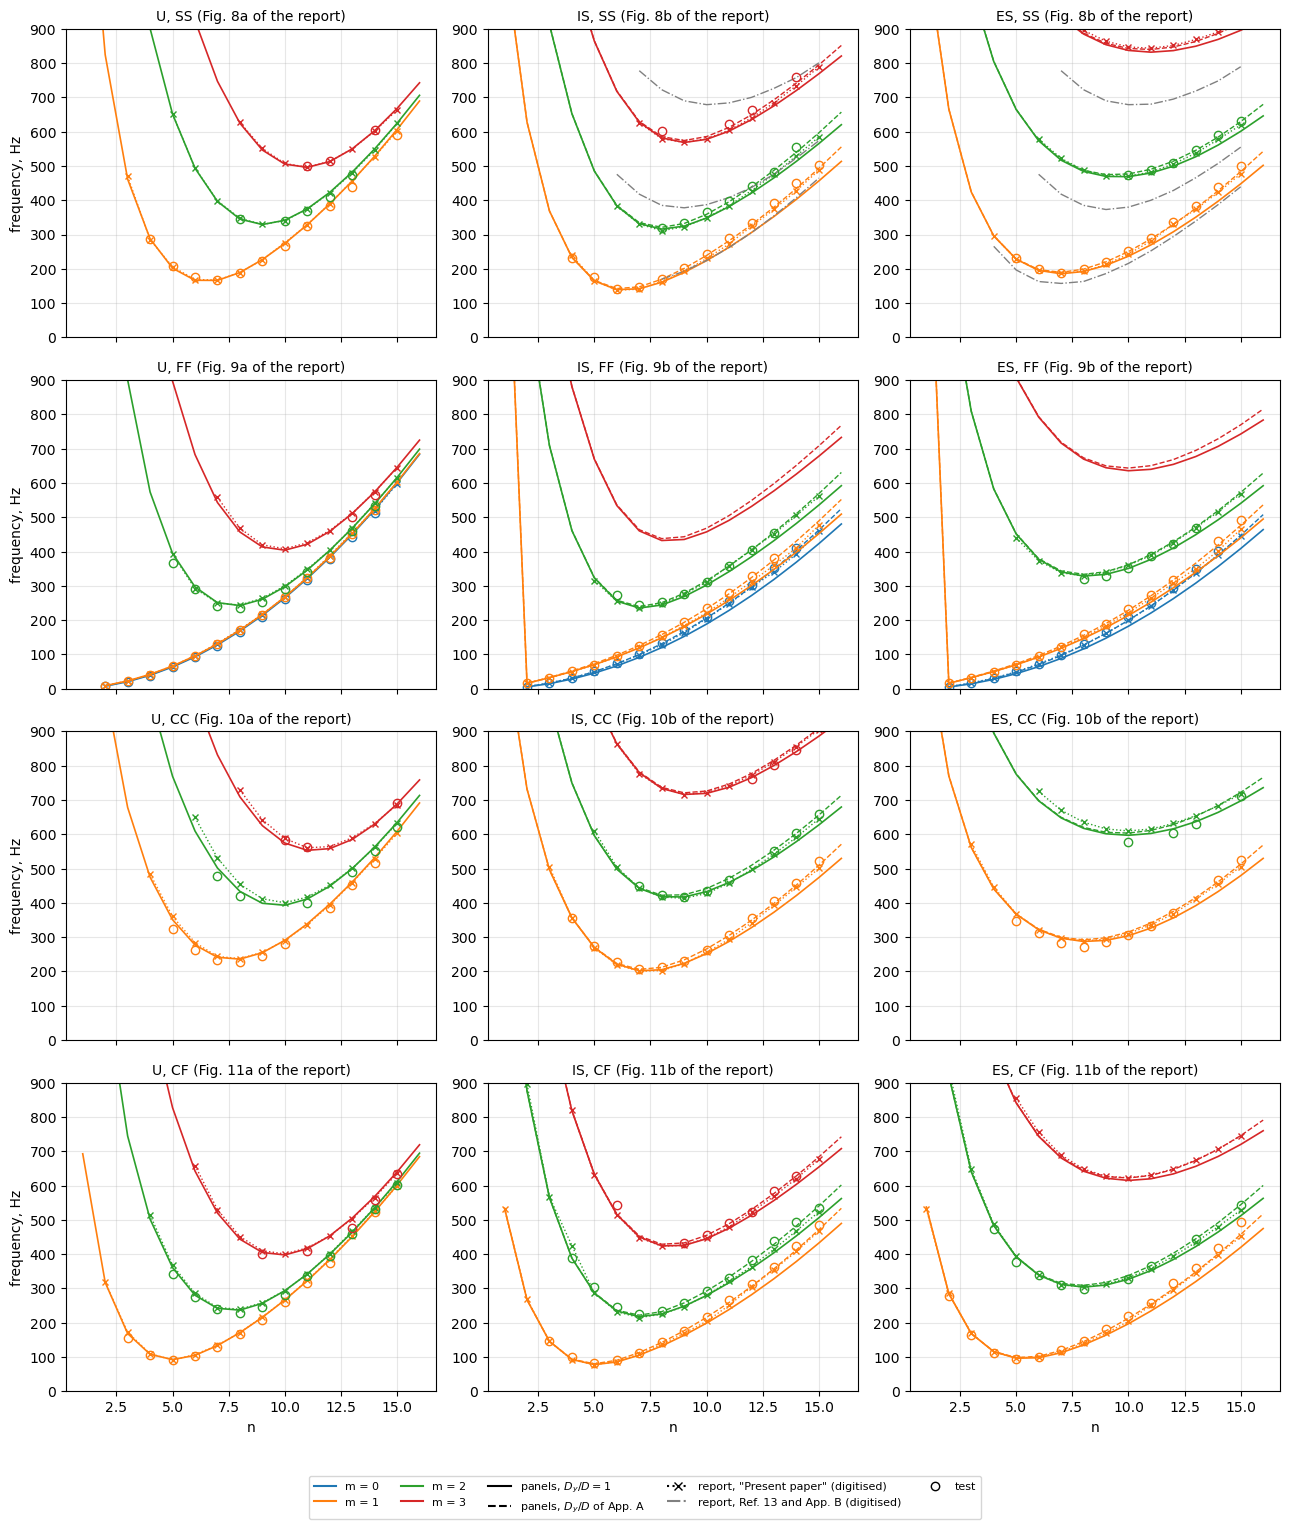

In [17]:
from matplotlib.lines import Line2D

fig, axes = plt.subplots(4, 3, figsize=(13, 15), sharex=True)
for i, bc in enumerate(BCS):
    for j, key in enumerate(('U', 'IS', 'ES')):
        ax = axes[i, j]
        for m in range(0, 4):
            color = 'C%d' % m
            for var, ls in ((0, '-'), (1, '--')):
                if (key, bc, var) not in FIN:
                    continue
                calc = FIN[(key, bc, var)]
                ns = sorted(n for (mm, n) in calc if mm == m and 1 <= n <= 16)
                if ns:
                    ax.plot(ns, [calc[(m, n)] for n in ns], ls, color=color, lw=1.2 if var == 0 else 1.)
            curve = CURVES.get((bc, key, 'present'), {})
            ns = sorted(n for (mm, n) in curve if mm == m)
            if ns:
                ax.plot(ns, [curve[(m, n)] for n in ns], ':', marker='x', ms=4, color=color, lw=1.)
            ref13 = CURVES.get((bc, key, 'ref13'), {})
            ns = sorted(n for (mm, n) in ref13 if mm == m)
            if ns:
                ax.plot(ns, [ref13[(m, n)] for n in ns], '-.', color='0.5', lw=1.)
            pts = [(n, v[0]) for (mm, n), v in TESTS[(key, bc)].items() if mm == m]
            if pts:
                ax.plot(*zip(*pts), 'o', mfc='none', color=color)
        ax.set_ylim(0, 900)
        ax.set_title('%s, %s (Fig. %s%s of the report)' % (key, bc, FIGURE[bc], 'a' if key == 'U' else 'b'),
                     fontsize=10)
        ax.grid(alpha=0.3)
        if j == 0:
            ax.set_ylabel('frequency, Hz')
        if i == 3:
            ax.set_xlabel('n')
handles = ([Line2D([], [], color='C%d' % m, label='m = %d' % m) for m in range(4)]
           + [Line2D([], [], color='k', ls='-', label='panels, $D_y/D = 1$'),
              Line2D([], [], color='k', ls='--', label='panels, $D_y/D$ of App. A'),
              Line2D([], [], color='k', ls=':', marker='x', label='report, "Present paper" (digitised)'),
              Line2D([], [], color='0.5', ls='-.', label='report, Ref. 13 and App. B (digitised)'),
              Line2D([], [], color='k', ls='', marker='o', mfc='none', label='test')])
fig.legend(handles=handles, loc='lower center', ncol=5, fontsize=8, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## Mode shapes

Normal displacement $w$ of the skin of the half cylinder, unrolled, for the mode of lowest frequency of the stiffened shells (excluding $n < 2$), $x$ along the axis and $\theta$ around the circumference; the dots mark the stringers.

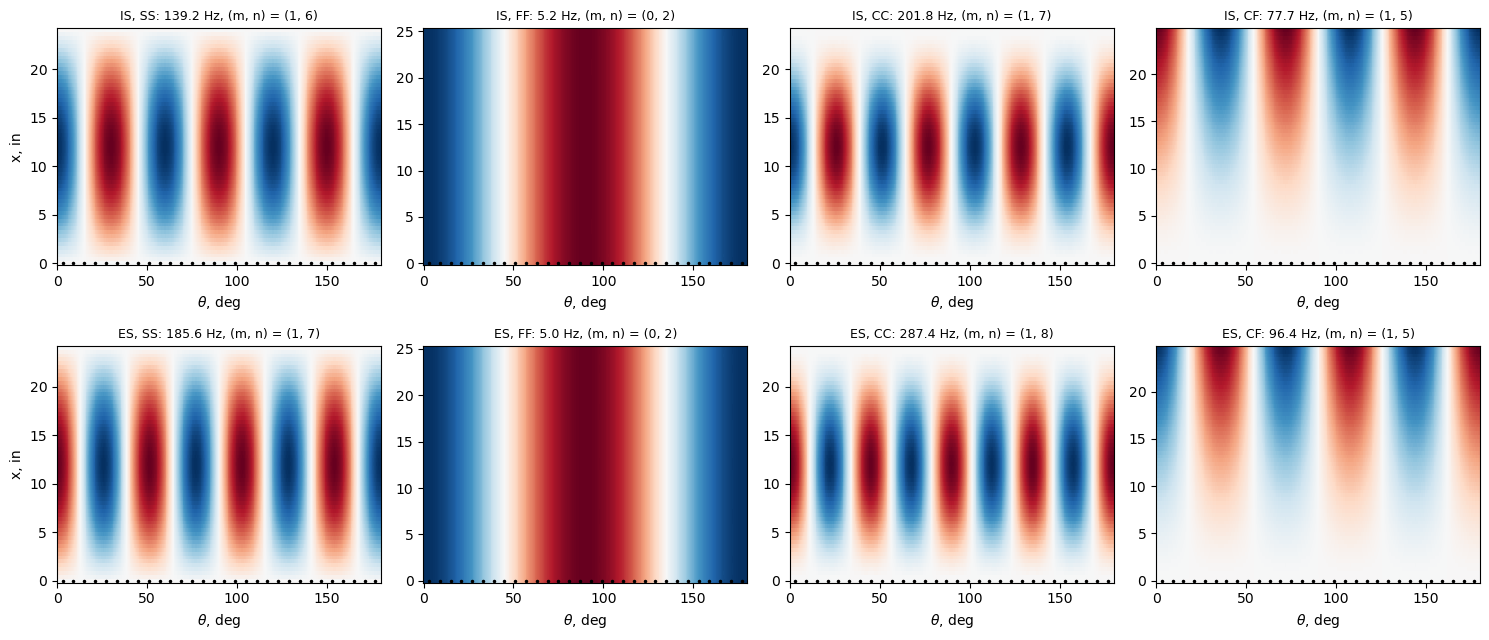

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for i, key in enumerate(('IS', 'ES')):
    t = TABLE_I[key]
    R = t['R']*IN
    for j, bc in enumerate(('SS', 'FF', 'CC', 'CF')):
        md, skin, (f, m, n, c) = MODES[(key, bc, 0)]
        x, th, w = bu.skin_w(md, c, skin, R)
        ax = axes[i, j]
        ax.pcolormesh(np.degrees(th), x/IN, (w/np.abs(w).max()).T, cmap='RdBu_r', shading='auto', vmin=-1, vmax=1)
        ax.plot(np.degrees((np.arange(NSTIFF//2) + 0.5)*2*np.pi/NSTIFF), np.zeros(NSTIFF//2), 'k.', ms=3)
        ax.set_title('%s, %s: %.1f Hz, (m, n) = (%d, %d)' % (key, bc, f, m, n), fontsize=9)
        ax.set_xlabel(r'$\theta$, deg')
        if j == 0:
            ax.set_ylabel('x, in')
plt.tight_layout()
plt.show()

## Sensitivities: coupling stiffness and skin thickness

Two quantities that the comparisons depend on, for the SS shells, with the last step of terms:

- $D_{12}$: the variant raises $D_{22}$ only, while the analysis of the report uses $D_1/D = \mu (D_x + D_y)/(2D) = 0.346$ (p. 17), i.e. $D_{12}$ multiplied by $(1 + D_y/D)/2$. The model with both factors is compared with the variant.
- $h$: the skin thicknesses of Table I are averages of up to 60 measurements (p. 6), and the IS skin (0.0266 in) is 4 % thicker than the ES skin (0.0256 in), although the models were designed to have the same skin thickness (p. 6). The report does not give the scatter of the measurements; the cell gives the change of the frequencies for a skin 2 % thicker ($D_y/D = 1$, blades unchanged), from which the effect of any other change follows approximately in proportion.

In [19]:
SENS = {}
for key in ('IS', 'ES'):
    t = TABLE_I[key]
    R = t['R']*IN
    tb, hb = BLADE[key]
    side = 'internal' if key == 'IS' else 'external'
    mx, ny, nyb = LEVELS[FINAL]
    for name, h, dyf, d12f in (('D12', t['h'], DY[key], (1 + DY[key])/2), ('h+2%', 1.02*t['h'], 1., 1.)):
        md, skin, blades = bu.build_cylinder(R, h*IN, LENGTH['SS']*IN, E, NU, RHO, nstiff=NSTIFF, tb=tb, hb=hb,
                side=side, bc='SS', mx=mx, ny=ny, nyb=nyb, Dy_factor=dyf, D12_factor=d12f)
        modes, dt, rres = bu.frequencies(md, skin, R, 'SS', num_eigvalues=NUM_EIGVALUES)
        SENS[(key, name)] = bu.lowest_by_mn(modes)
rows = []
for n in range(3, 16):
    row = ['%d' % n]
    for key in ('IS', 'ES'):
        base0, base1 = FIN[(key, 'SS', 0)].get((1, n)), FIN[(key, 'SS', 1)].get((1, n))
        f12, fh = SENS[(key, 'D12')].get((1, n)), SENS[(key, 'h+2%')].get((1, n))
        row += ['%+.2f%%' % pct(f12, base1) if f12 and base1 else '-',
                '%+.2f%%' % pct(fh, base0) if fh and base0 else '-']
    rows.append(row)
display(Markdown('**SS, m = 1: change of the frequency**'))
display(markdown_table(['n', 'IS, D_12 raised (vs D_y variant)', 'IS, h + 2 % (vs D_y/D = 1)',
                        'ES, D_12 raised (vs D_y variant)', 'ES, h + 2 % (vs D_y/D = 1)'], rows))
for key in ('IS', 'ES'):
    for name, var in (('D12', 1), ('h+2%', 0)):
        base = FIN[(key, 'SS', var)]
        d = [pct(SENS[(key, name)][mn], base[mn]) for mn in TESTS[(key, 'SS')]
             if mn in base and mn in SENS[(key, name)]]
        print('%s, %s: change over the measured (m, n), mean %+.2f%%, min. %+.2f%%, max. %+.2f%%'
              % (key, name, np.mean(d), min(d), max(d)))

**SS, m = 1: change of the frequency**

| n | IS, D_12 raised (vs D_y variant) | IS, h + 2 % (vs D_y/D = 1) | ES, D_12 raised (vs D_y variant) | ES, h + 2 % (vs D_y/D = 1) |
|---|---|---|---|---|
| 3 | +0.00% | +0.34% | +0.00% | +0.21% |
| 4 | +0.00% | +0.33% | +0.00% | +0.10% |
| 5 | +0.01% | +0.44% | +0.01% | +0.07% |
| 6 | +0.03% | +0.75% | +0.01% | +0.18% |
| 7 | +0.04% | +1.13% | +0.02% | +0.45% |
| 8 | +0.04% | +1.43% | +0.03% | +0.81% |
| 9 | +0.03% | +1.64% | +0.03% | +1.15% |
| 10 | +0.03% | +1.79% | +0.03% | +1.43% |
| 11 | +0.03% | +1.90% | +0.02% | +1.64% |
| 12 | +0.02% | +1.99% | +0.02% | +1.81% |
| 13 | +0.02% | +2.07% | +0.02% | +1.93% |
| 14 | +0.02% | +2.13% | +0.02% | +2.03% |
| 15 | +0.02% | +2.19% | +0.02% | +2.10% |

IS, D12: change over the measured (m, n), mean +0.04%, min. +0.00%, max. +0.05%
IS, h+2%: change over the measured (m, n), mean +1.14%, min. +0.30%, max. +2.19%
ES, D12: change over the measured (m, n), mean +0.03%, min. +0.01%, max. +0.04%
ES, h+2%: change over the measured (m, n), mean +1.05%, min. +0.07%, max. +2.10%


## Discussion

- **Convergence and symmetry.** In the last step of the convergence study the frequencies of the measured $(m, n)$ change by at most 0.36 %, for both variants, the half cylinder reproduces the frequencies of the full cylinder to within 0.001 %, and the numerically integrated skin (the route of the $D_y/D$ variant) reproduces the analytically integrated one to $2 \times 10^{-11}$.
- **Unstiffened shell.** `panels` agrees with the tests to 1.5 % to 3.1 % on average (mean absolute difference) for the four boundary conditions, with no free parameter, and with the analysis of the report ("Present paper" curves of Figs. 8(a) to 11(a)) to within $-1.1$ % to $-0.1$ % on average. The clamped values are 2.6 % to 2.8 % above the tests on average, the largest differences (up to 8.6 %) at the lowest $n$ of CC and CF, where the potting in a low-melting-point alloy (p. 7) is a less rigid clamp than $u = v = w = w_{,x} = 0$. The analysis of the report is also above the tests for CC, "almost 10 percent" at $(1, 5)$ and $(2, 7)$, which the report attributes mainly to the in-plane shear contradiction of its beam functions at a clamped end and, to a lesser extent, to external loading from the potting (p. 19); `panels` has no such contradiction (the Ritz functions satisfy $u = v = w = w_{,x} = 0$ and leave $N_{xy}$ free), and remains above the tests, which points to the end fixture.
- **Stiffened shells, stringers joined along a line ($D_y/D = 1$).** `panels` is within 6.5 % of the tests for $n \le 6$ with SS, CC and CF, e.g. the lowest SS frequencies, $(1, 6)$ for IS and $(1, 7)$ for ES, 2.0 % and 1.8 % below the tests, and the mean differences are $-3.2$ % to $-6.6$ % (ES, CC: $+0.2$ %). The frequencies fall increasingly below the tests as $n$ grows, to $-9$ % to $-15$ % at $n = 15$ for $m = 1$, and for the free-free modes $m = 0$ at all $n$: these modes bend the skin around the circumference, which the stringer roots, 0.100 in wide with fillets of 1/16 in on both sides (0.225 in of each 1.00 in pitch), stiffen and the model does not.
- **With $D_y/D$ of Appendix A.** Multiplying $D_{22}$ of the skin by 1.195 (IS) and 1.197 (ES) removes most of this trend: the mean differences against the tests become $-1.4$ % to $0.0$ % (IS) and $-0.6$ % to $+3.1$ % (ES), the mean absolute differences 1.0 % to 3.6 %, and the lowest SS frequencies agree to $+0.2$ % (IS) and $+0.4$ % (ES). This is the improvement stated in the summary of the report (p. 1), and the D_y/D recomputed here from Table I reproduces the values of Appendix A. Two groups remain apart: the free-free modes $(0, 2)$, 7 % below the tests ($-15$ % without $D_y/D$), whose measured values differ by up to 64 % between the two shakers (Table III), and the CC modes of the ES shell, now up to 7.4 % above the tests (lowest frequency, $(1, 8)$), as the unstiffened CC shell is; the report finds its own agreement for CC "not readily explainable" for the ES shell, "although the externally stiffened shell may have been subjected to more external loading" (p. 20).
- **Against the analysis of the report (digitised curves).** The curves are themselves below the tests for the IS shell (mean $+2.1$ % to $+3.7$ % test against curve) and closer for the ES shell ($-2.3$ % to $+2.2$ %). `panels` with $D_y/D = 1$ is below the curves by 1.2 % to 5.7 % on average, with $D_y/D$ above them by 0.5 % to 2.3 %; the reading precision, $\pm 2$ Hz, is 1 % at 200 Hz.
- **Against Egle and Sewall.** For $n \ge 4$, `panels` with $D_y/D$, the value of their Table 1, agrees with the discrete analysis to $+0.4$ % on average ($-2.5$ % to $+2.2$ %) and with the averaged one to $+0.1$ % ($-2.5$ % to $+1.7$ %); with $D_y/D = 1$ it is 1.9 % (discrete) and 2.1 % (averaged) below, up to 5.7 % and 6.1 % at $m = 1$, $n = 15$. For $n \le 3$ both variants are 2.4 % to 20 % below Table 2, the most at $m = 1$, $n = 1$, as expected from the in-surface inertia that Egle and Sewall neglect (p. 522) and `panels` includes; the entry $m = 1$, $n = 3$, read as 445.3, falls in this group ($-4.7$ % with $D_y/D$).

**Possible sources of the differences, including the original models.**

- **Smeared and discrete stringers.** For this shell, with 60 closely spaced stringers, smearing is not a source of difference: Egle and Sewall find their discrete and averaged analyses within 1 % (p. 523), the measured circumferential modes are close to a single harmonic, and the digitised curve of the report agrees with the averaged column within the reading precision for $m = 2$ and 3. The stringer model differs: beams with the section constants of Table 1 in both analyses, plate strips here, whose section differs from Table I by $-1.2$ % to $-1.4$ % in area and $-0.7$ % in $J_e$.
- **The root stiffness applied to the whole skin.** $D_y/D$ is a smeared correction from a strain-energy equivalence in pure circumferential bending with the neutral surface at the mid-height of the shell-stringer combination (p. 23); the report applies it to the whole shell, Egle and Sewall to their discrete-stringer shell, and the variant here to every skin panel, while the real stiffening is concentrated at the roots. The choice of the effective thickness $h(y)$ is "somewhat arbitrary" (p. 23); the report bounds $D_y/D$ between 1.11 (no fillets) and 1.29 (infinitely thick roots) and finds it "not particularly affected by wide variations in the choice of $h(y)$" within the profile (p. 26). With the values of Appendix A the stiffened shells are 0.5 % to 2.3 % above the curves of the report and agree with the tests on average, so the data do not call for a larger factor; a model of the roots themselves (a thicker skin strip under each stringer, or the fillets as plates) would replace the factor and was not attempted. The coupling term changes little: raising $D_{12}$ as the report does ($D_1/D = 0.346$, p. 17) changes the SS frequencies by at most 0.05 %.
- **Fillets.** The plate strips start at the middle surface of the skin, an overlap of $h/2$ that approximately replaces the area of the fillets (section table above); the fillets enter the model through $D_y/D$ only.
- **In-surface inertia.** Egle and Sewall neglect it to reduce the order of their eigenvalue problem by a factor of 3 (p. 522); the comparison above quantifies the effect, up to 20 % at $n = 1$ and below 2.5 % for $n \ge 4$. The averaged column also omits the eccentricity inertia; against the curve of the report, which keeps both, the difference is within 2.7 %.
- **Misprints and inconsistencies of the sources.** Table 2: "44.53" read as 445.3, and the averaged 424.2 at $m = 1$, $n = 12$ left out (the curve of the report gives 329.8 Hz there). Table 1: $p_s' = 0.1668$ in is 1.2 % below $\sqrt{J_{e_s}/A_s}$ of Table I, without effect on the frequencies. Appendix A: the simplified values of p. 26 differ from the recomputed ones in the last digit. Otherwise the values of Appendix A and the stringer section of Table I ($A_s$, $ar{z}_s$, $J_{e_s}$ of the ES shell, within 0.2 %) were reproduced.
- **End fixtures.** SS: knife-edge rings inside and outside; "motion normal to the shell between stiffeners was not restrained on the stiffened side of the shell" (p. 7), while the model restrains the skin along the whole edge and the blades radially. CC and CF: potting 1/2 in deep, with residual external loads that "it was not possible" to eliminate completely (p. 8). The clamped cases are those with the largest positive differences, for both the unstiffened and the stiffened shells.
- **Thickness scatter.** The dimensions of Table I are averages of up to 60 measurements (p. 6), and the scatter is not reported. A skin 2 % thicker raises the SS frequencies by 0.1 % to 2.2 %, most at high $n$, about the size of the remaining mean differences; the IS and ES skins differ by 4 % (0.0266 and 0.0256 in) although the models were designed to the same thickness (p. 6).
- **Other differences.** The two welded longitudinal seams, where the skin tapers to 0.035 in at the butt (Fig. 1), are not modelled, nor the mass of the shaker attachment. The dual resonances, two frequencies for the same $(m, n)$, show that the test shells were not perfectly axisymmetric (p. 11); the model, symmetric by construction, gives one frequency per $(m, n)$, compared with the mean of the pair. The electrodynamic and the air shaker give frequencies of the lowest free-free modes that differ by up to 64 % ($n = 2$, Table III), the measure of the uncertainty of these modes; the air-shaker values are used.